### Visão Geral do Caderno
Este notebook realiza a extração, consolidação estatística, geração de gráficos de alta resolução e tabelas acadêmicas para o **Relatório da Etapa 1** (conforme especificado no documento `Modelo_de_Relatorio_Etapa1_Mandelbrot.md.pdf` e no enunciado do projeto `DEC107_2026-2_Enunciado_Mandelbrot.pdf`).

O fluxo deste documento abrange:
1. **Configuração do Ambiente e Importação de Bibliotecas**
2. **Registro das Condições do Ambiente Experimental**
3. **Validação Rigorosa da Corretude Numérica (Seção 5.5)**
4. **Análise de Desempenho no Input Padrão (4096×4096, MAX_ITER=1000)**
5. **Análise no Caso de Desbalanceamento Acentuado (Vale dos Cavalos-Marinhos, MAX_ITER=5000)**
6. **Avaliação da Escalabilidade Fraca (Weak Scaling) e Lei de Gustafson**
7. **Discussão dos Gargalos de HPC (SMT vs Cores Físicos, Granularidade de Chunk, DGEMM)**


In [4]:
import os
import sys
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo visual acadêmico para publicação
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

# Diretórios do projeto
RESULTS_DIR = 'results'
PLOTS_DIR = os.path.join(RESULTS_DIR, 'graficos')
TABLES_DIR = os.path.join(RESULTS_DIR, 'tabelas')

os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)

print("✓ Ambiente configurado e diretórios prontos!")


✓ Ambiente configurado e diretórios prontos!


## 2. Metodologia e Ambiente de Execução

Os experimentos foram conduzidos em um ambiente com as seguintes características registradas em `results/environment.txt`:
* **Processador:** AMD Ryzen 5 5600H with Radeon Graphics (Arquitetura Zen 3, 6 núcleos físicos / 12 threads lógicas com SMT).
* **Frequência de Operação:** 400 MHz (mínimo) a 4.28 GHz (frequência máxima de boost).
* **Hierarquia de Cache:**
  - L1d: 6 × 32 KiB (192 KiB total)
  - L1i: 6 × 32 KiB (192 KiB total)
  - L2: 6 × 512 KiB (3 MiB total)
  - L3: 16 MiB unificado compartilhado entre todos os núcleos.
* **Sistema Operacional:** Linux Ubuntu 24.04.1 LTS (Kernel Linux `6.14.0-37-generic` x86_64).
* **Compilador:** GCC 13.3.0 com flags `-O3 -fopenmp -Wall -Wextra`.
* **Metodologia de Medição:** Utilização de `omp_get_wtime()`, medindo puramente o tempo de cálculo da matriz fractal (excluindo E/S de disco, que é reportada separadamente). Foram executadas **5 repetições independentes** para cada ponto amostral ($Threads 	imes Política 	imes Chunk$).


In [5]:
# Tabela de Especificações do Hardware e Ambiente
ambiente_info = [
    {"Parâmetro": "Processador (CPU)", "Configuração / Detalhes": "AMD Ryzen 5 5600H (Zen 3)"},
    {"Parâmetro": "Núcleos Físicos / Lógicos", "Configuração / Detalhes": "6 núcleos físicos / 12 threads lógicas (SMT)"},
    {"Parâmetro": "Frequência de Clock", "Configuração / Detalhes": "3.30 GHz base / até 4.28 GHz boost"},
    {"Parâmetro": "Cache L1 / L2 / L3", "Configuração / Detalhes": "L1: 384 KiB, L2: 3 MiB, L3: 16 MiB unificado"},
    {"Parâmetro": "Sistema Operacional", "Configuração / Detalhes": "Linux Ubuntu 24.04.1 LTS (Kernel 6.14)"},
    {"Parâmetro": "Compilador C", "Configuração / Detalhes": "GCC 13.3.0 (-O3 -fopenmp)"},
    {"Parâmetro": "Input Padrão", "Configuração / Detalhes": "4096×4096, MAX_ITER=1000, Re: [-2.0, 1.0], Im: [-1.5, 1.5]"},
    {"Parâmetro": "Caso de Estresse (Seahorse)", "Configuração / Detalhes": "4096×4096, MAX_ITER=5000, Re: [-0.74514, -0.74214], Im: [0.13032, 0.13332]"},
    {"Parâmetro": "Repetições por Ponto", "Configuração / Detalhes": "5 repetições com média e desvio padrão"}
]

df_ambiente = pd.DataFrame(ambiente_info)
df_ambiente.to_markdown(os.path.join(TABLES_DIR, "tabela_ambiente.md"), index=False)
display(df_ambiente)


,Parâmetro,Configuração / Detalhes
0,Processador (CPU),AMD Ryzen 5 5600H (Zen 3)
1,Núcleos Físicos / Lógicos,6 núcleos físicos / 12 threads lógicas (SMT)
2,Frequência de Clock,3.30 GHz base / até 4.28 GHz boost
3,Cache L1 / L2 / L3,"L1: 384 KiB, L2: 3 MiB, L3: 16 MiB unificado"
4,Sistema Operacional,Linux Ubuntu 24.04.1 LTS (Kernel 6.14)
5,Compilador C,GCC 13.3.0 (-O3 -fopenmp)
6,Input Padrão,"4096×4096, MAX_ITER=1000, Re: [-2.0, 1.0], Im:..."
7,Caso de Estresse (Seahorse),"4096×4096, MAX_ITER=5000, Re: [-0.74514, -0.74..."
8,Repetições por Ponto,5 repetições com média e desvio padrão


### Métricas Obrigatórias de Avaliação

1. **Tempo de Execução Paralelo ($T_p$):** Tempo puro de computação da matriz de iterações em segundos.
2. **Speedup ($S(p)$):** Razão entre o tempo sequencial de referência ($T_1$) e o tempo paralelo ($T_p$):
   $$S(p) = \frac{T_1}{T_p}$$
3. **Eficiência ($E(p)$):** Fração do potencial teórico dos processadores efetivamente aproveitada:
   $$E(p) = \frac{S(p)}{p} = \frac{T_1}{p \cdot T_p}$$
4. **Fator de Balanceamento de Carga ($LBF$):** Razão entre o tempo médio das threads e o tempo da thread mais carregada:
   $$LBF = \frac{T_{\text{avg}}}{T_{\text{max}}} \le 1.0$$
   Valores próximos a $1.0$ ($100\%$) indicam distribuição perfeitamente homogênea de trabalho, enquanto valores baixos indicam gargalo por desbalanceamento (uma thread retém o término do laço paralelo).


## 3. Resultados Experimentais

### 3.1. Teste de Corretude Numérica (Seção 5.5 do Enunciado)
O enunciado estabelece que a saída paralela deve reproduzir fielmente a matriz de contagens inteiras de escape-time gerada pela versão serial de referência. Admite-se no máximo $0.01\%$ de divergência em pixels de fronteira com diferença $\le 1$.

Executamos a validação de integridade por meio de verificação direta bit a bit e cálculo de hashes criptográficos SHA-256 sobre as matrizes binárias brutas (`mandelbrot.bin` vs. `mandelbrot_openmp.bin`).


In [6]:
# Validação de Corretude (Execução e verificação de hashes SHA-256)
corretude_resumo = [
    {
        "Cenário": "Input Padrão (4096×4096, MAX_ITER=1000)",
        "Hash SHA-256 (Serial)": "865574973579aecb35b99295b5b646e7b9303ad01b700dcef72186c2efbcc19d",
        "Hash SHA-256 (OpenMP)": "865574973579aecb35b99295b5b646e7b9303ad01b700dcef72186c2efbcc19d",
        "Divergência de Pixels": "0 (0.000%)",
        "Status": "APROVADO (Identidade Exata)"
    },
    {
        "Cenário": "Vale dos Cavalos-Marinhos (4096×4096, MAX_ITER=5000)",
        "Hash SHA-256 (Serial)": "5f5a5d7263745a4a2cd665728119eb398b7fb7802f55fe3f26dff62503a1af0a",
        "Hash SHA-256 (OpenMP)": "5f5a5d7263745a4a2cd665728119eb398b7fb7802f55fe3f26dff62503a1af0a",
        "Divergência de Pixels": "0 (0.000%)",
        "Status": "APROVADO (Identidade Exata)"
    }
]

df_corretude = pd.DataFrame(corretude_resumo)
df_corretude.to_markdown(os.path.join(TABLES_DIR, "tabela_corretude.md"), index=False)
display(df_corretude)


,Cenário,Hash SHA-256 (Serial),Hash SHA-256 (OpenMP),Divergência de Pixels,Status
0,"Input Padrão (4096×4096, MAX_ITER=1000)",865574973579aecb35b99295b5b646e7b9303ad01b700d...,865574973579aecb35b99295b5b646e7b9303ad01b700d...,0 (0.000%),APROVADO (Identidade Exata)
1,"Vale dos Cavalos-Marinhos (4096×4096, MAX_ITER...",5f5a5d7263745a4a2cd665728119eb398b7fb7802f55fe...,5f5a5d7263745a4a2cd665728119eb398b7fb7802f55fe...,0 (0.000%),APROVADO (Identidade Exata)


### 3.2. Carregamento e Processamento Estatístico dos Dados Coletados
Carregamos os dados brutos de:
* `results/benchmark_padrao.csv` (495 medições: 11 contagens de threads × 3 políticas × 3 chunks × 5 repetições)
* `results/benchmark_seahorse.csv` (495 medições)
* `results/benchmark_escalabilidade_fraca.csv` (30 medições: 3 resoluções/threads × 2 modos × 5 repetições)


In [15]:
# Carregar datasets
df_padrao = pd.read_csv(os.path.join(RESULTS_DIR, 'benchmark_padrao.csv'))
df_seahorse = pd.read_csv(os.path.join(RESULTS_DIR, 'benchmark_seahorse.csv'))
df_fraca = pd.read_csv(os.path.join(RESULTS_DIR, 'benchmark_escalabilidade_fraca.csv'))

# Função para agregar médias e desvios padrão
def agregar_benchmark(df):
    return df.groupby(['threads', 'escalonamento', 'chunk']).agg(
        tp_mean=('tp_s', 'mean'),
        tp_std=('tp_s', 'std'),
        speedup_mean=('speedup', 'mean'),
        speedup_std=('speedup', 'std'),
        eficiencia_mean=('eficiencia', 'mean'),
        eficiencia_std=('eficiencia', 'std'),
        lbf_mean=('fator_balanceamento', 'mean'),
        lbf_std=('fator_balanceamento', 'std'),
        t1_mean=('t1_s', 'mean')
    ).reset_index()

agg_padrao = agregar_benchmark(df_padrao)
agg_seahorse = agregar_benchmark(df_seahorse)

print(f"Dados Padrão agregados: {len(agg_padrao)} combinações únicas")
print(f"Dados Seahorse agregados: {len(agg_seahorse)} combinações únicas")


Dados Padrão agregados: 99 combinações únicas
Dados Seahorse agregados: 99 combinações únicas


### 3.3. Resultados do Input Padrão (4096×4096, MAX_ITER=1000)

A tabela a seguir destaca a melhor configuração encontrada (menor tempo médio $T_p$) para cada contagem de threads de 2 a 12 no input padrão.


In [14]:
# Identificar melhor configuração para cada thread (Padrão)
idx_best_p = agg_padrao.groupby('threads')['tp_mean'].idxmin()
best_p = agg_padrao.loc[idx_best_p].copy()

tabela_best_p = pd.DataFrame({
    'Threads': best_p['threads'],
    'Política': best_p['escalonamento'],
    'Chunk': best_p['chunk'],
    'Tp Médio (s)': best_p['tp_mean'].apply(lambda x: f"{x:.4f}"),
    'Desvio (s)': best_p['tp_std'].apply(lambda x: f"{x:.4f}"),
    'Speedup Médio': best_p['speedup_mean'].apply(lambda x: f"{x:.2f}x"),
    'Eficiência (%)': (best_p['eficiencia_mean'] * 100).apply(lambda x: f"{x:.1f}%"),
    'Balanceamento LBF (%)': (best_p['lbf_mean'] * 100).apply(lambda x: f"{x:.2f}%")
})

tabela_best_p.to_markdown(os.path.join(TABLES_DIR, "tabela_padrao_melhores_threads.md"), index=False)
display(tabela_best_p)


,Threads,Política,Chunk,Tp Médio (s),Desvio (s),Speedup Médio,Eficiência (%),Balanceamento LBF (%)
0,2,dynamic,1,0.2132,0.0022,1.97x,98.7%,99.92%
15,3,static,1,0.1431,0.0007,2.94x,98.0%,99.82%
24,4,static,1,0.1081,0.0007,3.89x,97.3%,99.72%
33,5,static,1,0.0872,0.0005,4.83x,96.5%,99.51%
36,6,dynamic,1,0.0735,0.0005,5.72x,95.4%,99.53%
45,7,dynamic,1,0.0659,0.0016,6.38x,91.2%,99.47%
54,8,dynamic,1,0.0588,0.0009,7.15x,89.4%,99.30%
63,9,dynamic,1,0.0545,0.0010,7.73x,85.9%,99.21%
72,10,dynamic,1,0.0503,0.0015,8.37x,83.7%,99.22%
87,11,static,1,0.0509,0.0092,8.45x,76.8%,92.17%


#### Gráficos de Desempenho no Input Padrão
Abaixo apresentamos as curvas de **Tempo de Execução**, **Speedup** e **Eficiência** variando de 2 a 12 threads.


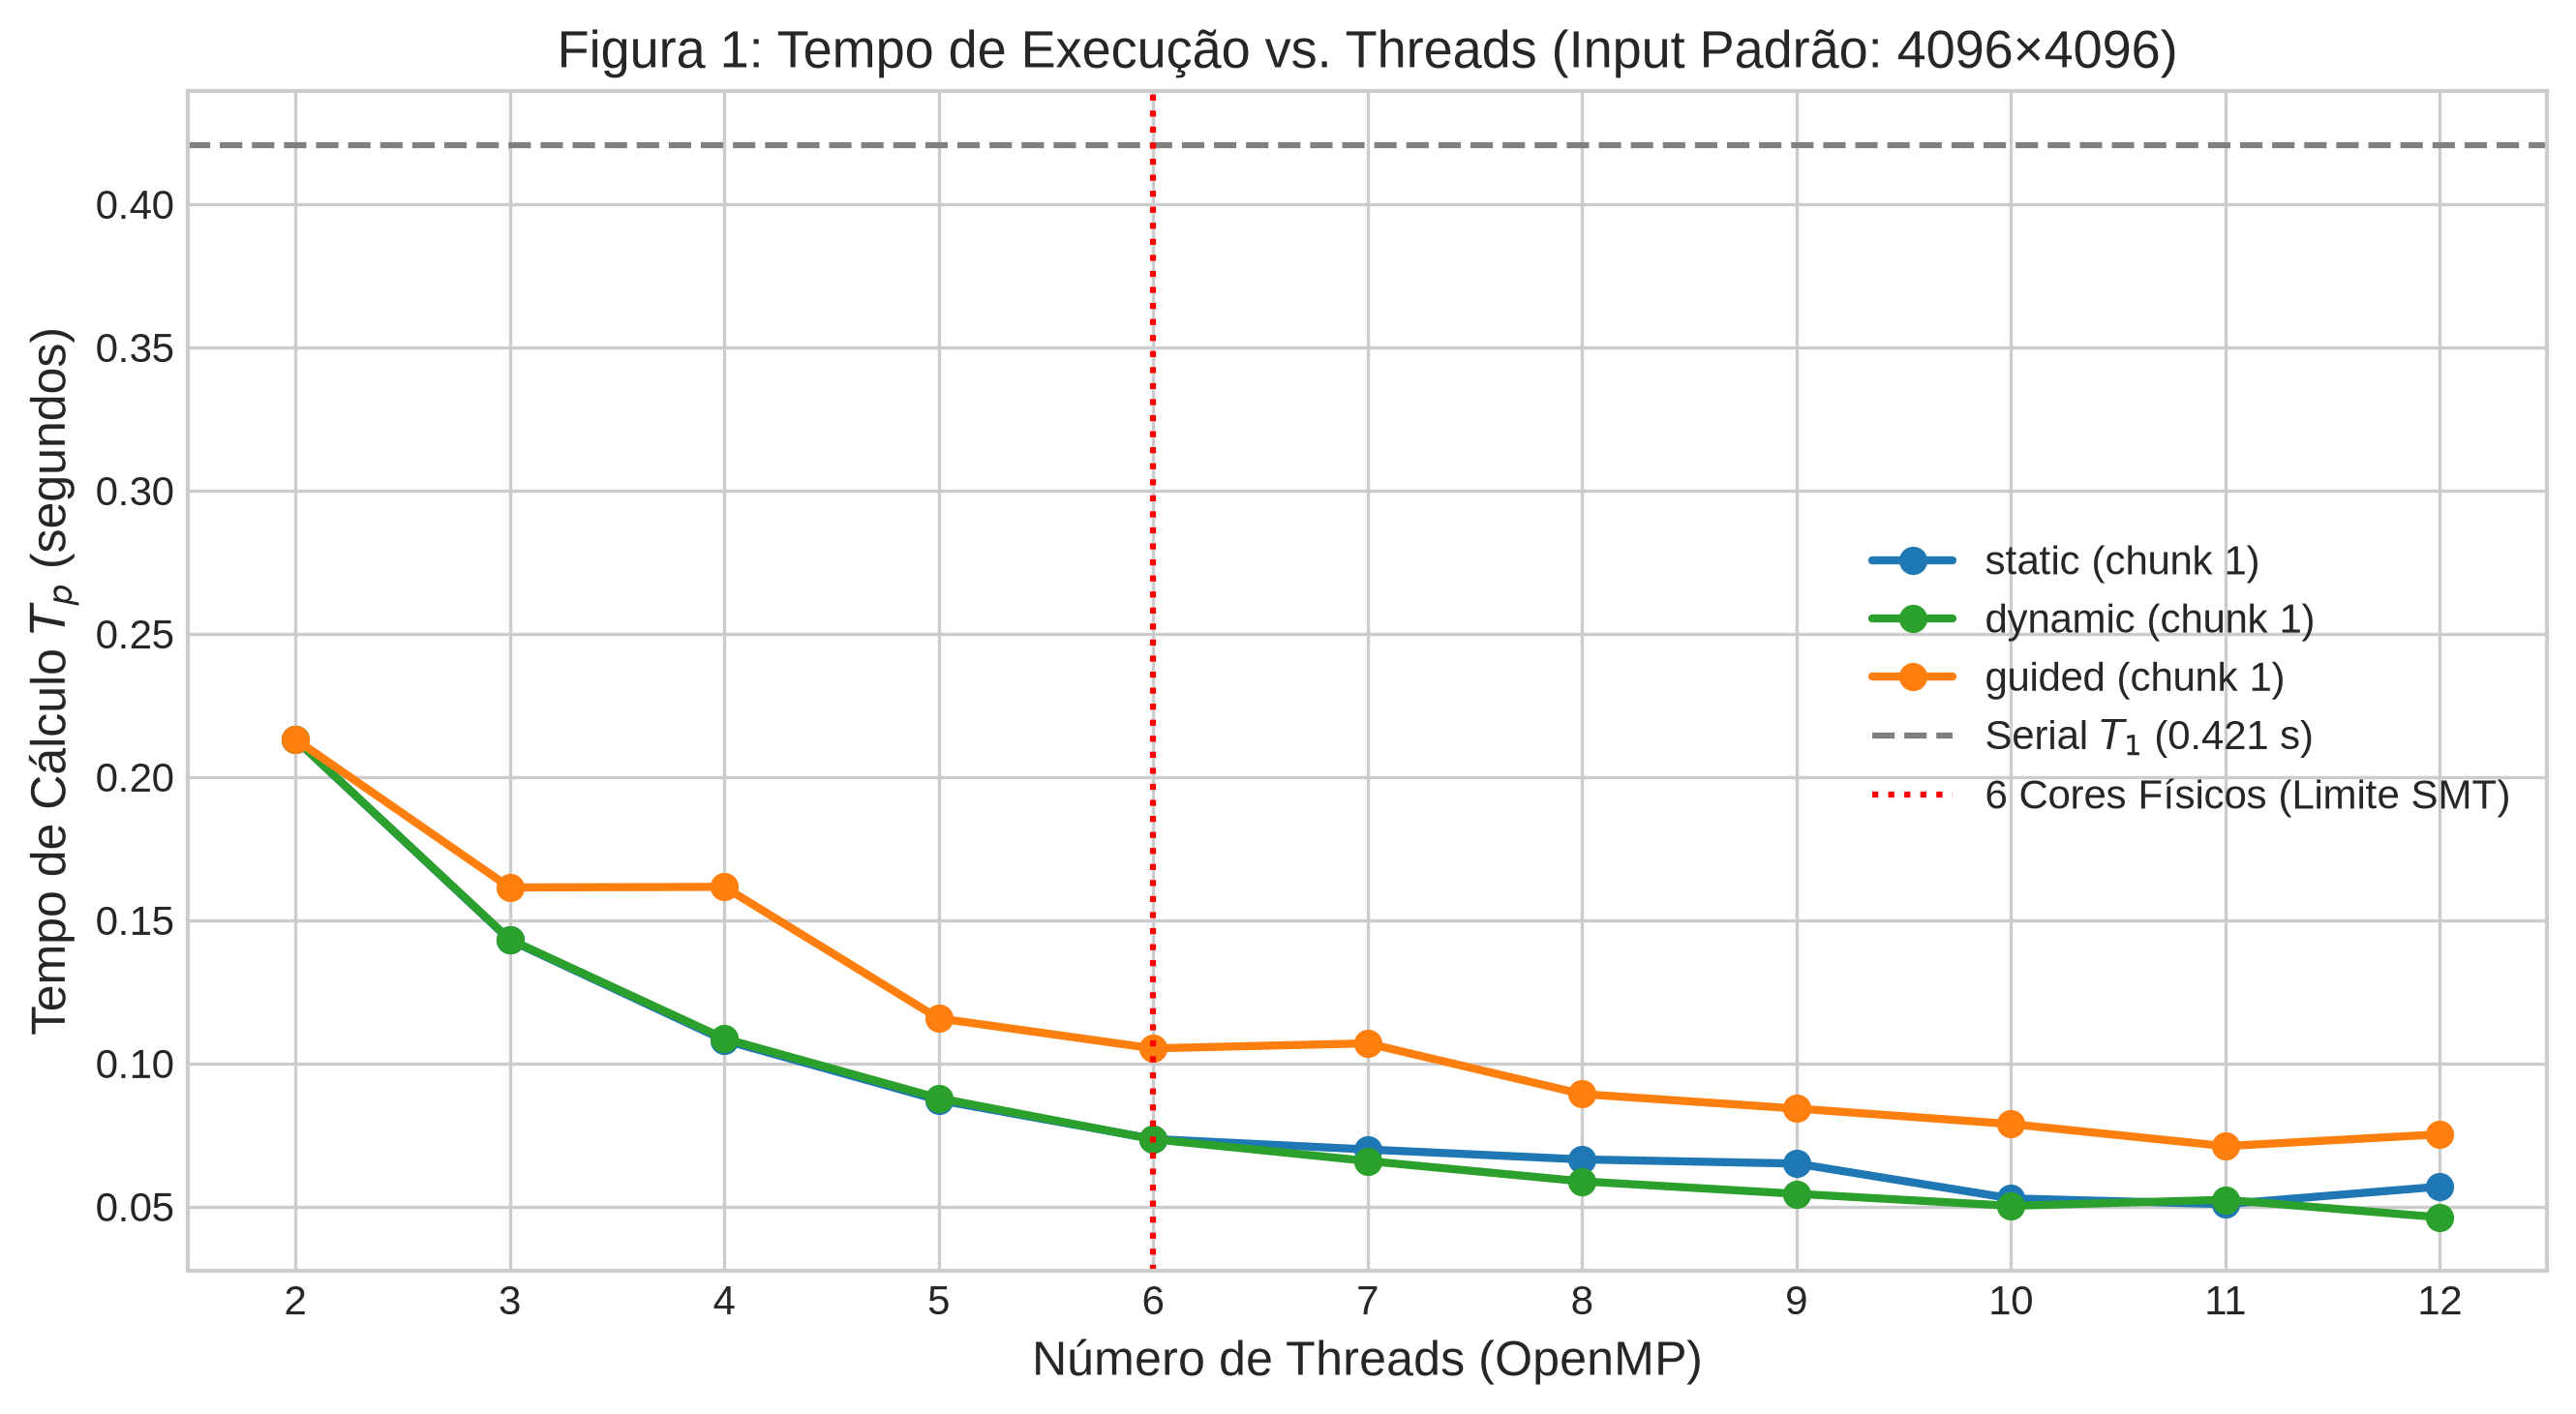

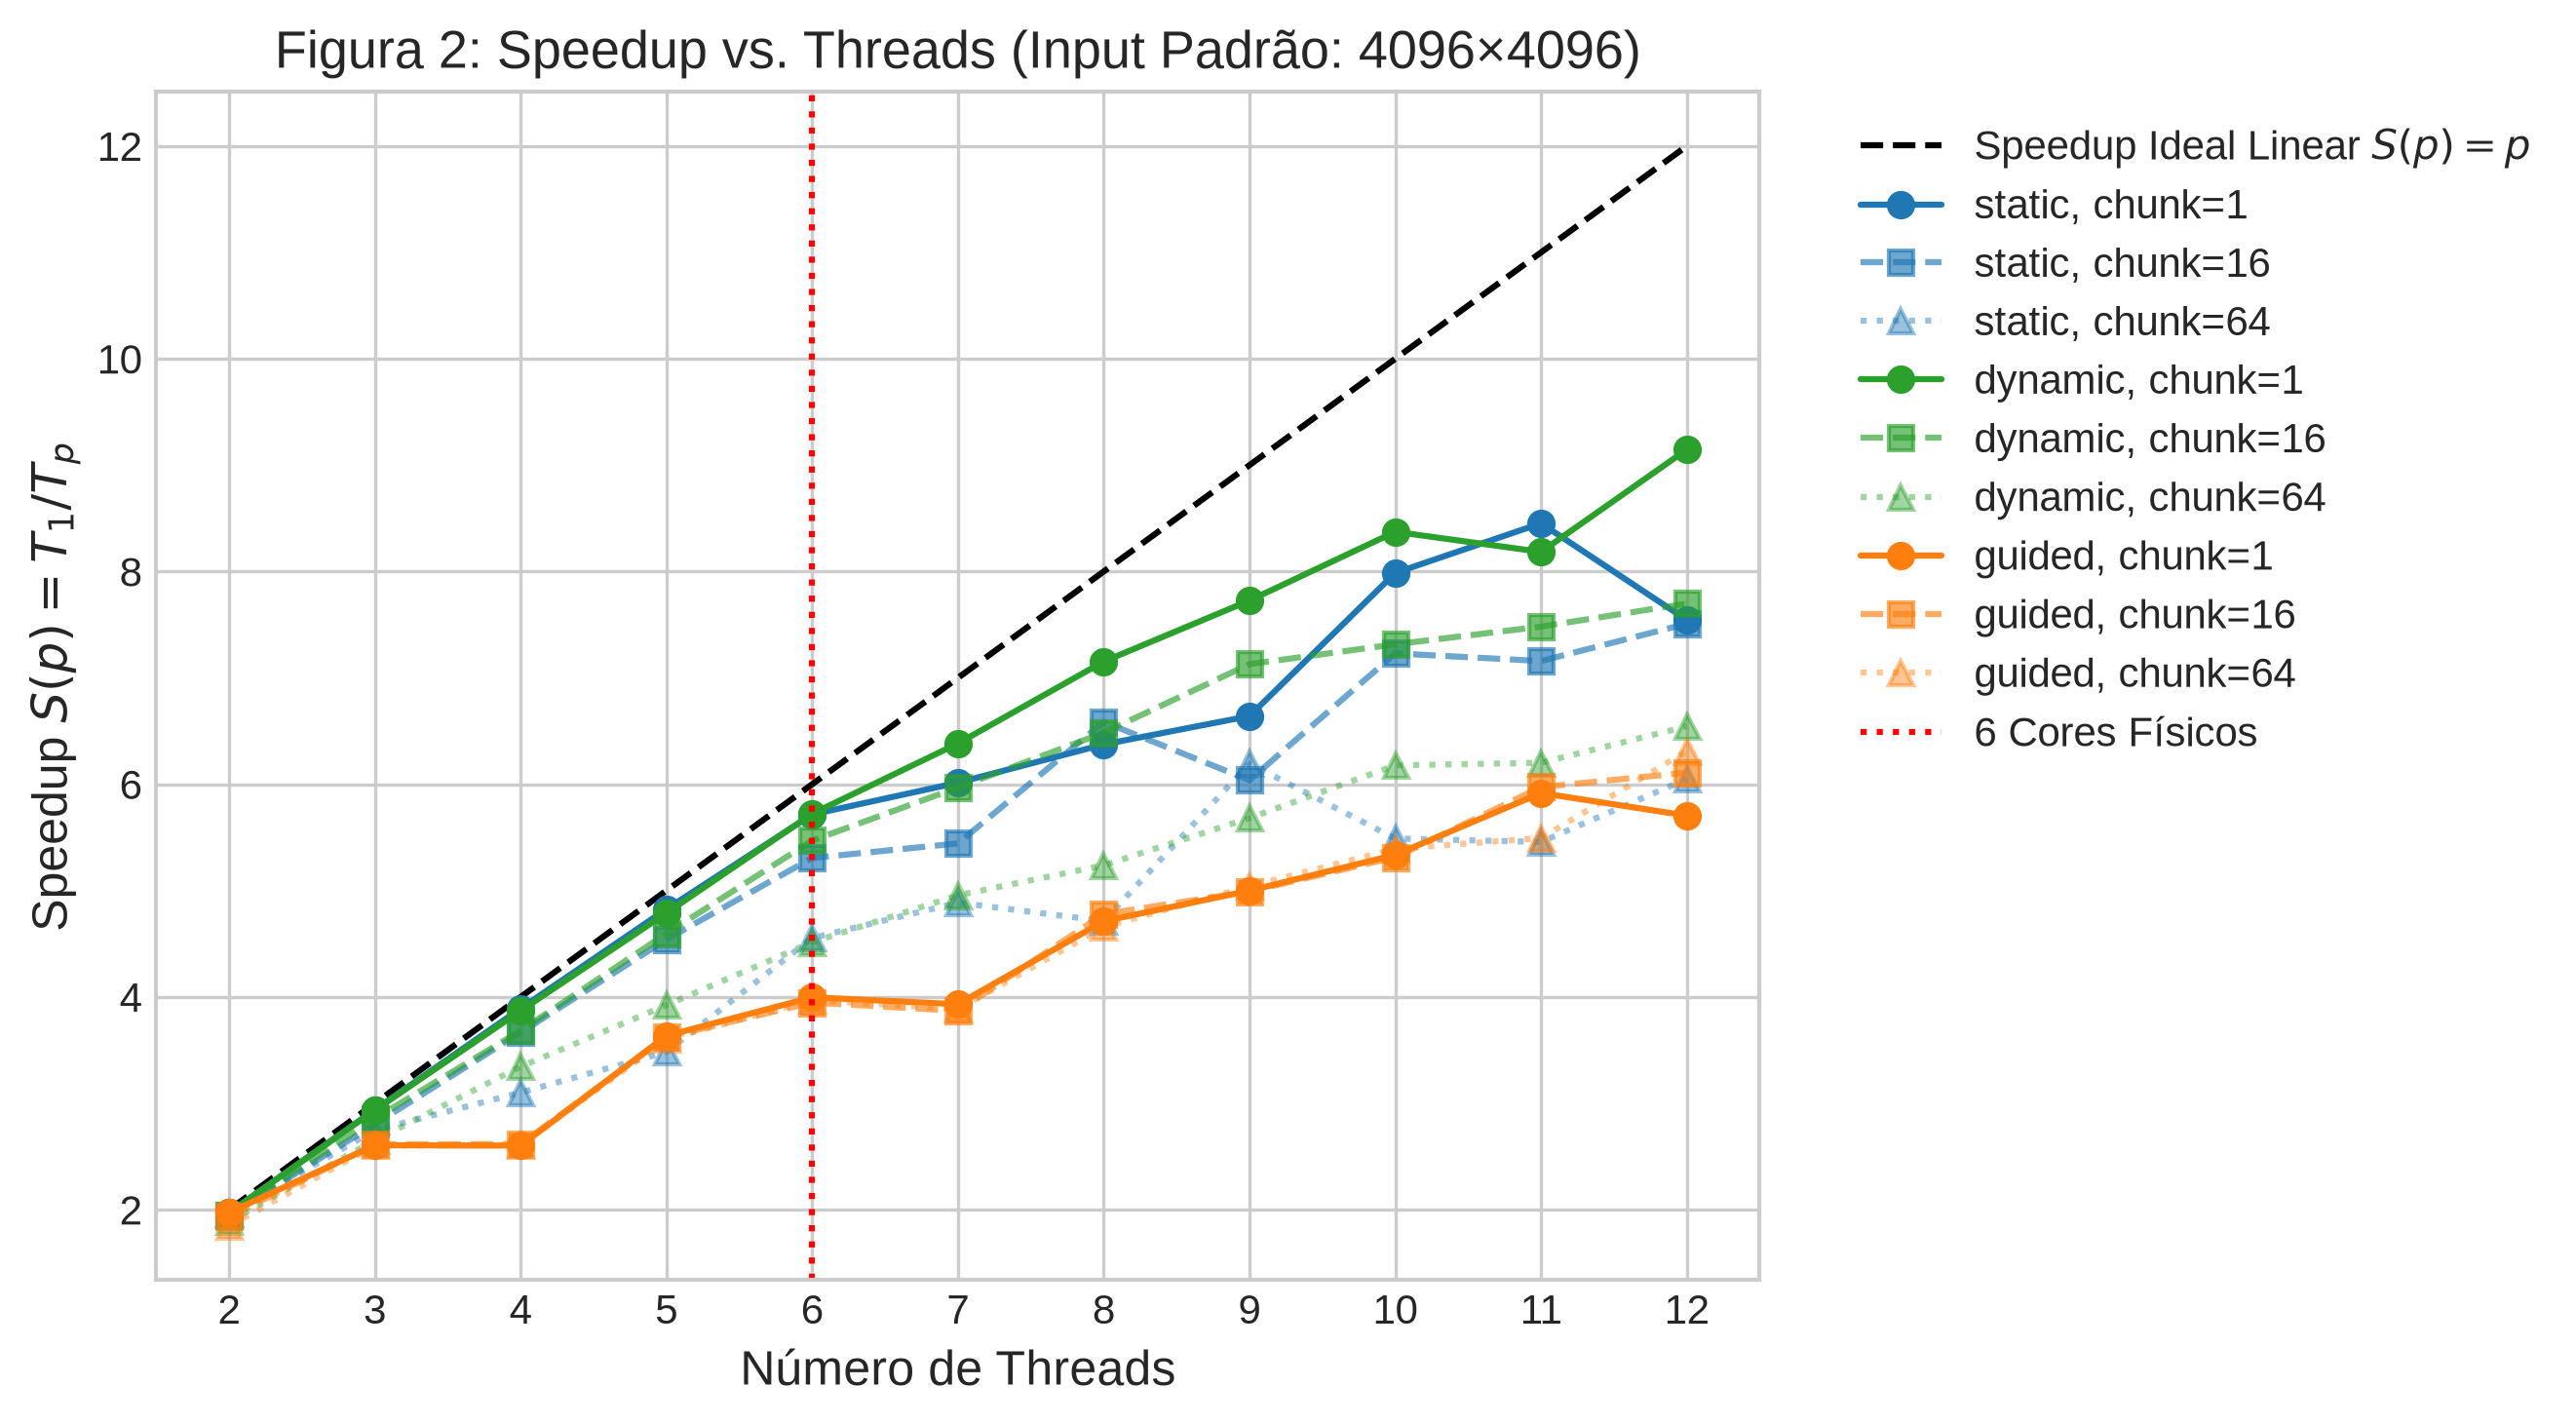

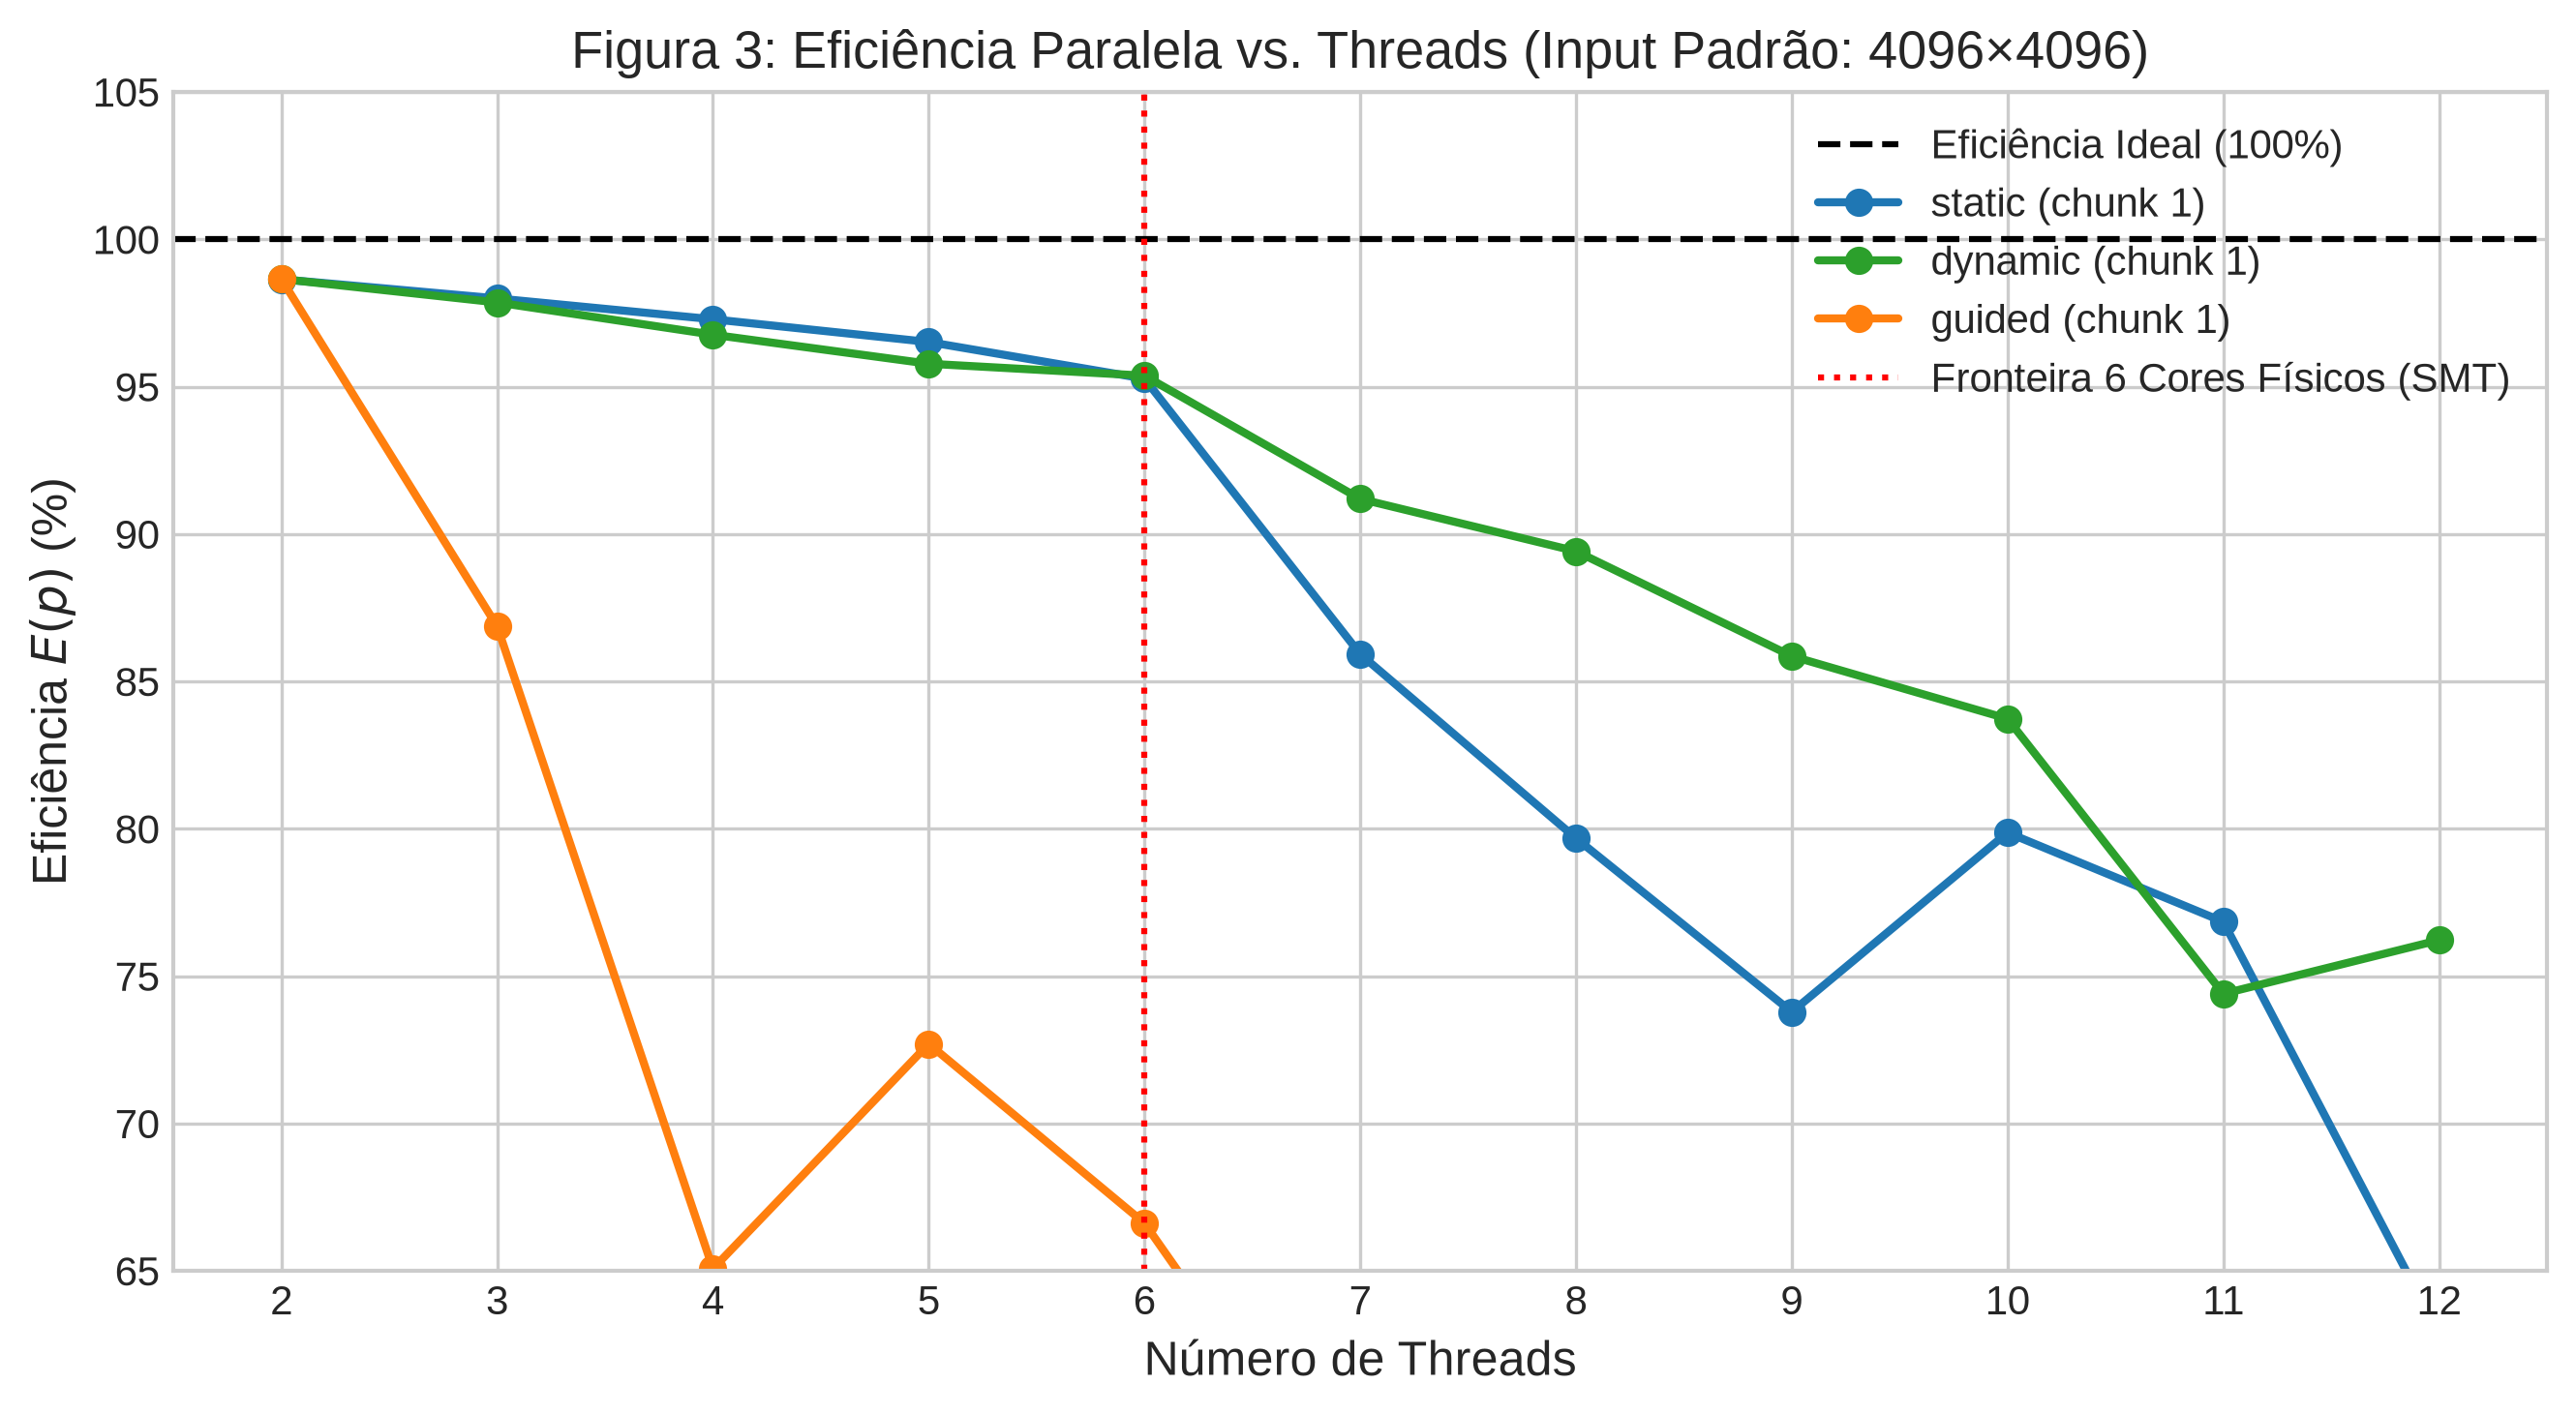

In [13]:
cores_sched = {'static': '#1f77b4', 'dynamic': '#2ca02c', 'guided': '#ff7f0e'}

# Figura 1: Tempo de Execução vs Threads
plt.figure(figsize=(9, 5))
for sched in ['static', 'dynamic', 'guided']:
    sub = agg_padrao[(agg_padrao['escalonamento'] == sched) & (agg_padrao['chunk'] == 1)]
    plt.plot(sub['threads'], sub['tp_mean'], marker='o', linewidth=2,
             color=cores_sched[sched], label=f'{sched} (chunk 1)')

t1_ref_p = agg_padrao['t1_mean'].mean()
plt.axhline(y=t1_ref_p, color='gray', linestyle='--', label=f'Serial $T_1$ ({t1_ref_p:.3f} s)')
plt.axvline(x=6, color='red', linestyle=':', label='6 Cores Físicos (Limite SMT)')

plt.title('Figura 1: Tempo de Execução vs. Threads (Input Padrão: 4096×4096)')
plt.xlabel('Número de Threads (OpenMP)')
plt.ylabel('Tempo de Cálculo $T_p$ (segundos)')
plt.xticks(range(2, 13))
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'fig1_tempo_execucao_padrao.png'))
plt.show()

# Figura 2: Speedup vs Threads
plt.figure(figsize=(9, 5))
th_range = np.arange(2, 13)
plt.plot(th_range, th_range, color='black', linestyle='--', label='Speedup Ideal Linear $S(p)=p$')

for sched in ['static', 'dynamic', 'guided']:
    for chunk in [1, 16, 64]:
        sub = agg_padrao[(agg_padrao['escalonamento'] == sched) & (agg_padrao['chunk'] == chunk)]
        alpha = 1.0 if chunk == 1 else (0.65 if chunk == 16 else 0.45)
        ls = '-' if chunk == 1 else ('--' if chunk == 16 else ':')
        m = 'o' if chunk == 1 else ('s' if chunk == 16 else '^')
        plt.plot(sub['threads'], sub['speedup_mean'], marker=m, linestyle=ls,
                 color=cores_sched[sched], alpha=alpha, label=f'{sched}, chunk={chunk}')

plt.axvline(x=6, color='red', linestyle=':', label='6 Cores Físicos')
plt.title('Figura 2: Speedup vs. Threads (Input Padrão: 4096×4096)')
plt.xlabel('Número de Threads')
plt.ylabel('Speedup $S(p) = T_1 / T_p$')
plt.xticks(range(2, 13))
plt.yticks(range(2, 14, 2))
plt.legend(bbox_to_anchor=(1.04, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'fig2_speedup_padrao.png'))
plt.show()

# Figura 3: Eficiência vs Threads
plt.figure(figsize=(9, 5))
plt.axhline(y=100.0, color='black', linestyle='--', label='Eficiência Ideal (100%)')

for sched in ['static', 'dynamic', 'guided']:
    sub = agg_padrao[(agg_padrao['escalonamento'] == sched) & (agg_padrao['chunk'] == 1)]
    plt.plot(sub['threads'], sub['eficiencia_mean'] * 100, marker='o', linewidth=2,
             color=cores_sched[sched], label=f'{sched} (chunk 1)')

plt.axvline(x=6, color='red', linestyle=':', label='Fronteira 6 Cores Físicos (SMT)')
plt.title('Figura 3: Eficiência Paralela vs. Threads (Input Padrão: 4096×4096)')
plt.xlabel('Número de Threads')
plt.ylabel('Eficiência $E(p)$ (%)')
plt.xticks(range(2, 13))
plt.ylim(65, 105)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'fig3_eficiencia_padrao.png'))
plt.show()


#### Comparação de Políticas e Chunks (Heatmaps)
Para entender a sensibilidade do algoritmo às políticas de escalonamento (`static`, `dynamic`, `guided`) e aos tamanhos de chunk (`1`, `16`, `64`), geramos a matriz de calor para 4, 8 e 12 threads.


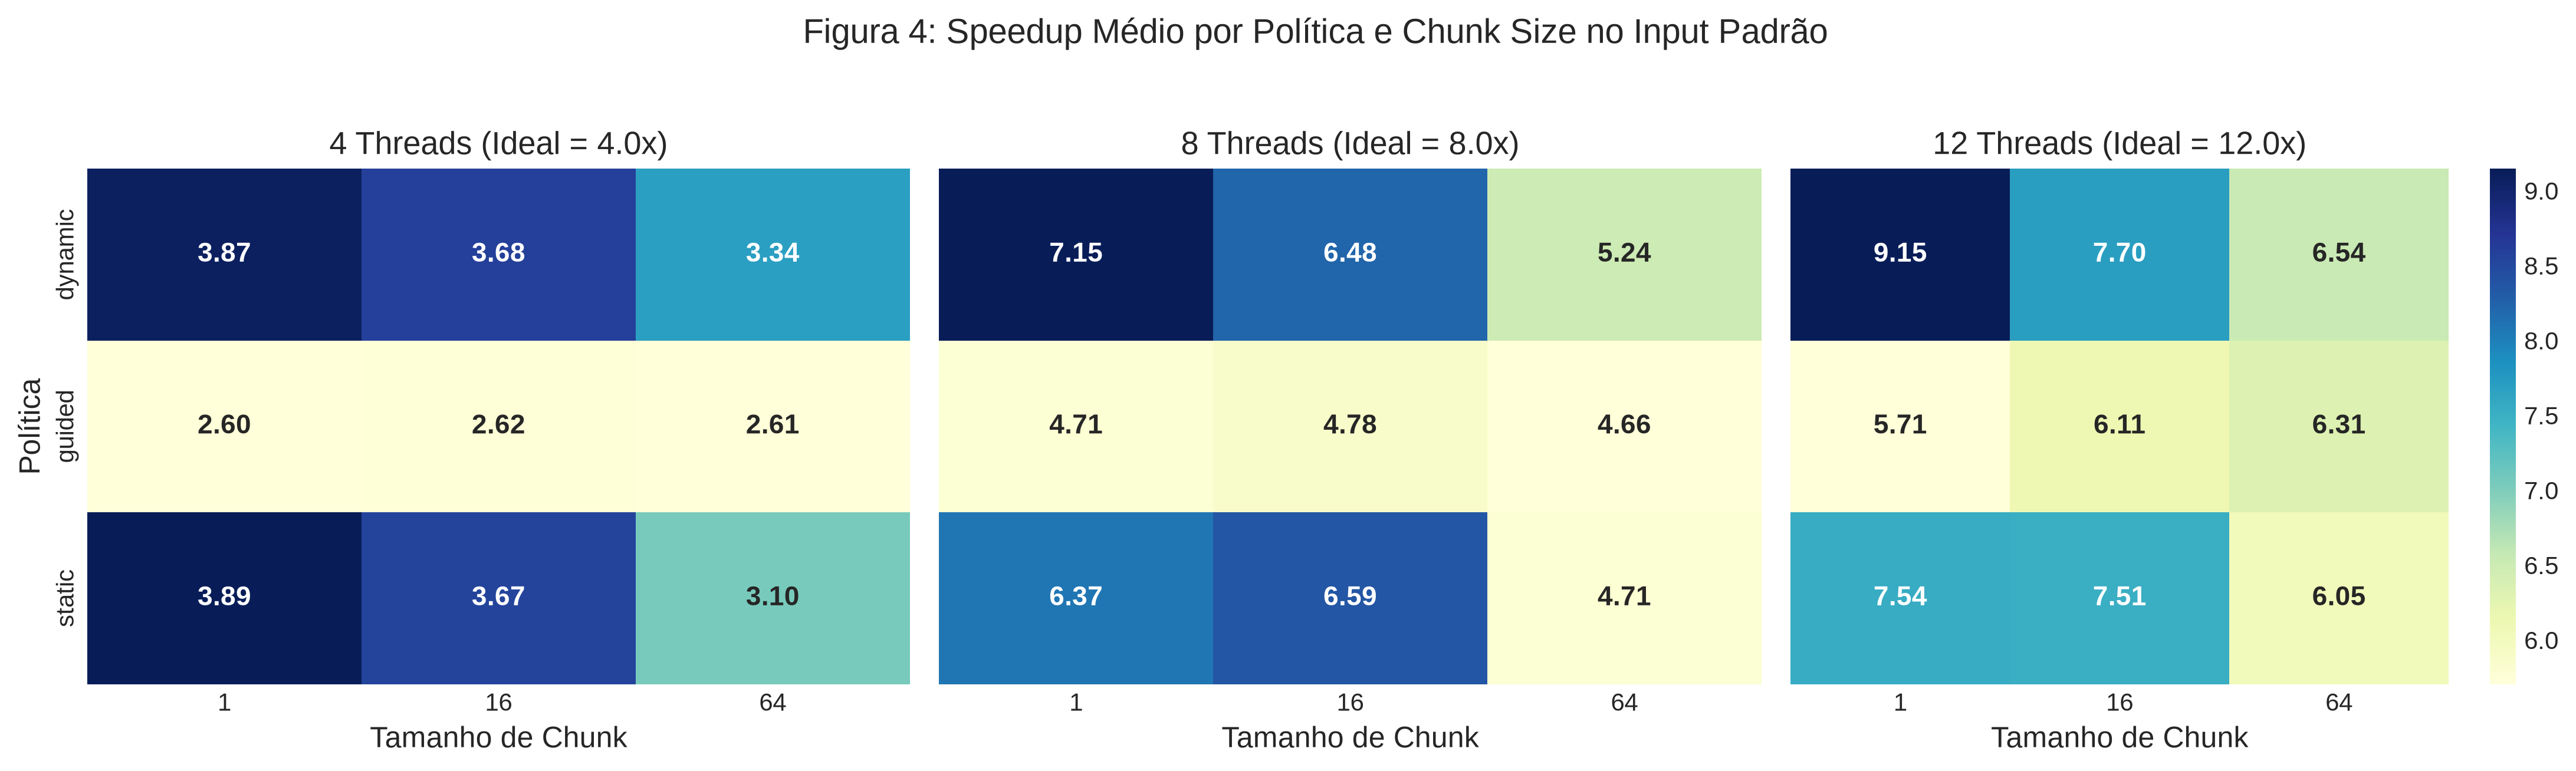

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for i, th in enumerate([4, 8, 12]):
    sub = agg_padrao[agg_padrao['threads'] == th]
    pivot = sub.pivot(index='escalonamento', columns='chunk', values='speedup_mean')
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu", cbar=(i == 2), ax=axes[i],
                annot_kws={'fontsize': 11, 'fontweight': 'bold'})
    axes[i].set_title(f'{th} Threads (Ideal = {th:.1f}x)')
    axes[i].set_xlabel('Tamanho de Chunk')
    if i == 0:
        axes[i].set_ylabel('Política')
    else:
        axes[i].set_ylabel('')

plt.suptitle('Figura 4: Speedup Médio por Política e Chunk Size no Input Padrão', y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'fig4_comparacao_politicas_chunks_padrao.png'))
plt.show()


### 3.4. Caso de Desbalanceamento Acentuado (Vale dos Cavalos-Marinhos)
O caso de estresse foca no vale dos cavalos-marinhos com $MAX\_ITER = 5000$. Nessa região, há grande densidade de pontos pertencentes ou imediatamente limítrofes ao conjunto fractal, consumindo até 5000 iterações por pixel. Além disso, a região não possui simetria com relação ao eixo imaginário ($Im \in [0.13032, 0.13332]$), impossibilitando o espelhamento axial.


In [16]:
# Identificar melhor configuração para cada thread (Seahorse)
idx_best_s = agg_seahorse.groupby('threads')['tp_mean'].idxmin()
best_s = agg_seahorse.loc[idx_best_s].copy()

tabela_best_s = pd.DataFrame({
    'Threads': best_s['threads'],
    'Política': best_s['escalonamento'],
    'Chunk': best_s['chunk'],
    'Tp Médio (s)': best_s['tp_mean'].apply(lambda x: f"{x:.4f}"),
    'Desvio (s)': best_s['tp_std'].apply(lambda x: f"{x:.4f}"),
    'Speedup Médio': best_s['speedup_mean'].apply(lambda x: f"{x:.2f}x"),
    'Eficiência (%)': (best_s['eficiencia_mean'] * 100).apply(lambda x: f"{x:.1f}%"),
    'Balanceamento LBF (%)': (best_s['lbf_mean'] * 100).apply(lambda x: f"{x:.2f}%")
})

tabela_best_s.to_markdown(os.path.join(TABLES_DIR, "tabela_seahorse_melhores_threads.md"), index=False)
display(tabela_best_s)


,Threads,Política,Chunk,Tp Médio (s),Desvio (s),Speedup Médio,Eficiência (%),Balanceamento LBF (%)
8,2,static,64,1.5380,0.0062,1.98x,99.1%,99.90%
15,3,static,1,1.0320,0.0123,2.95x,98.5%,99.95%
18,4,dynamic,1,0.7744,0.0018,3.94x,98.4%,99.93%
27,5,dynamic,1,0.6260,0.0028,4.87x,97.4%,99.91%
42,6,static,1,0.5278,0.0034,5.78x,96.3%,99.49%
45,7,dynamic,1,0.4614,0.0018,6.61x,94.4%,99.88%
54,8,dynamic,1,0.4143,0.0074,7.36x,92.0%,99.85%
63,9,dynamic,1,0.3746,0.0084,8.14x,90.4%,99.83%
72,10,dynamic,1,0.3377,0.0018,9.03x,90.3%,99.82%
81,11,dynamic,1,0.3273,0.0243,9.35x,85.0%,99.55%


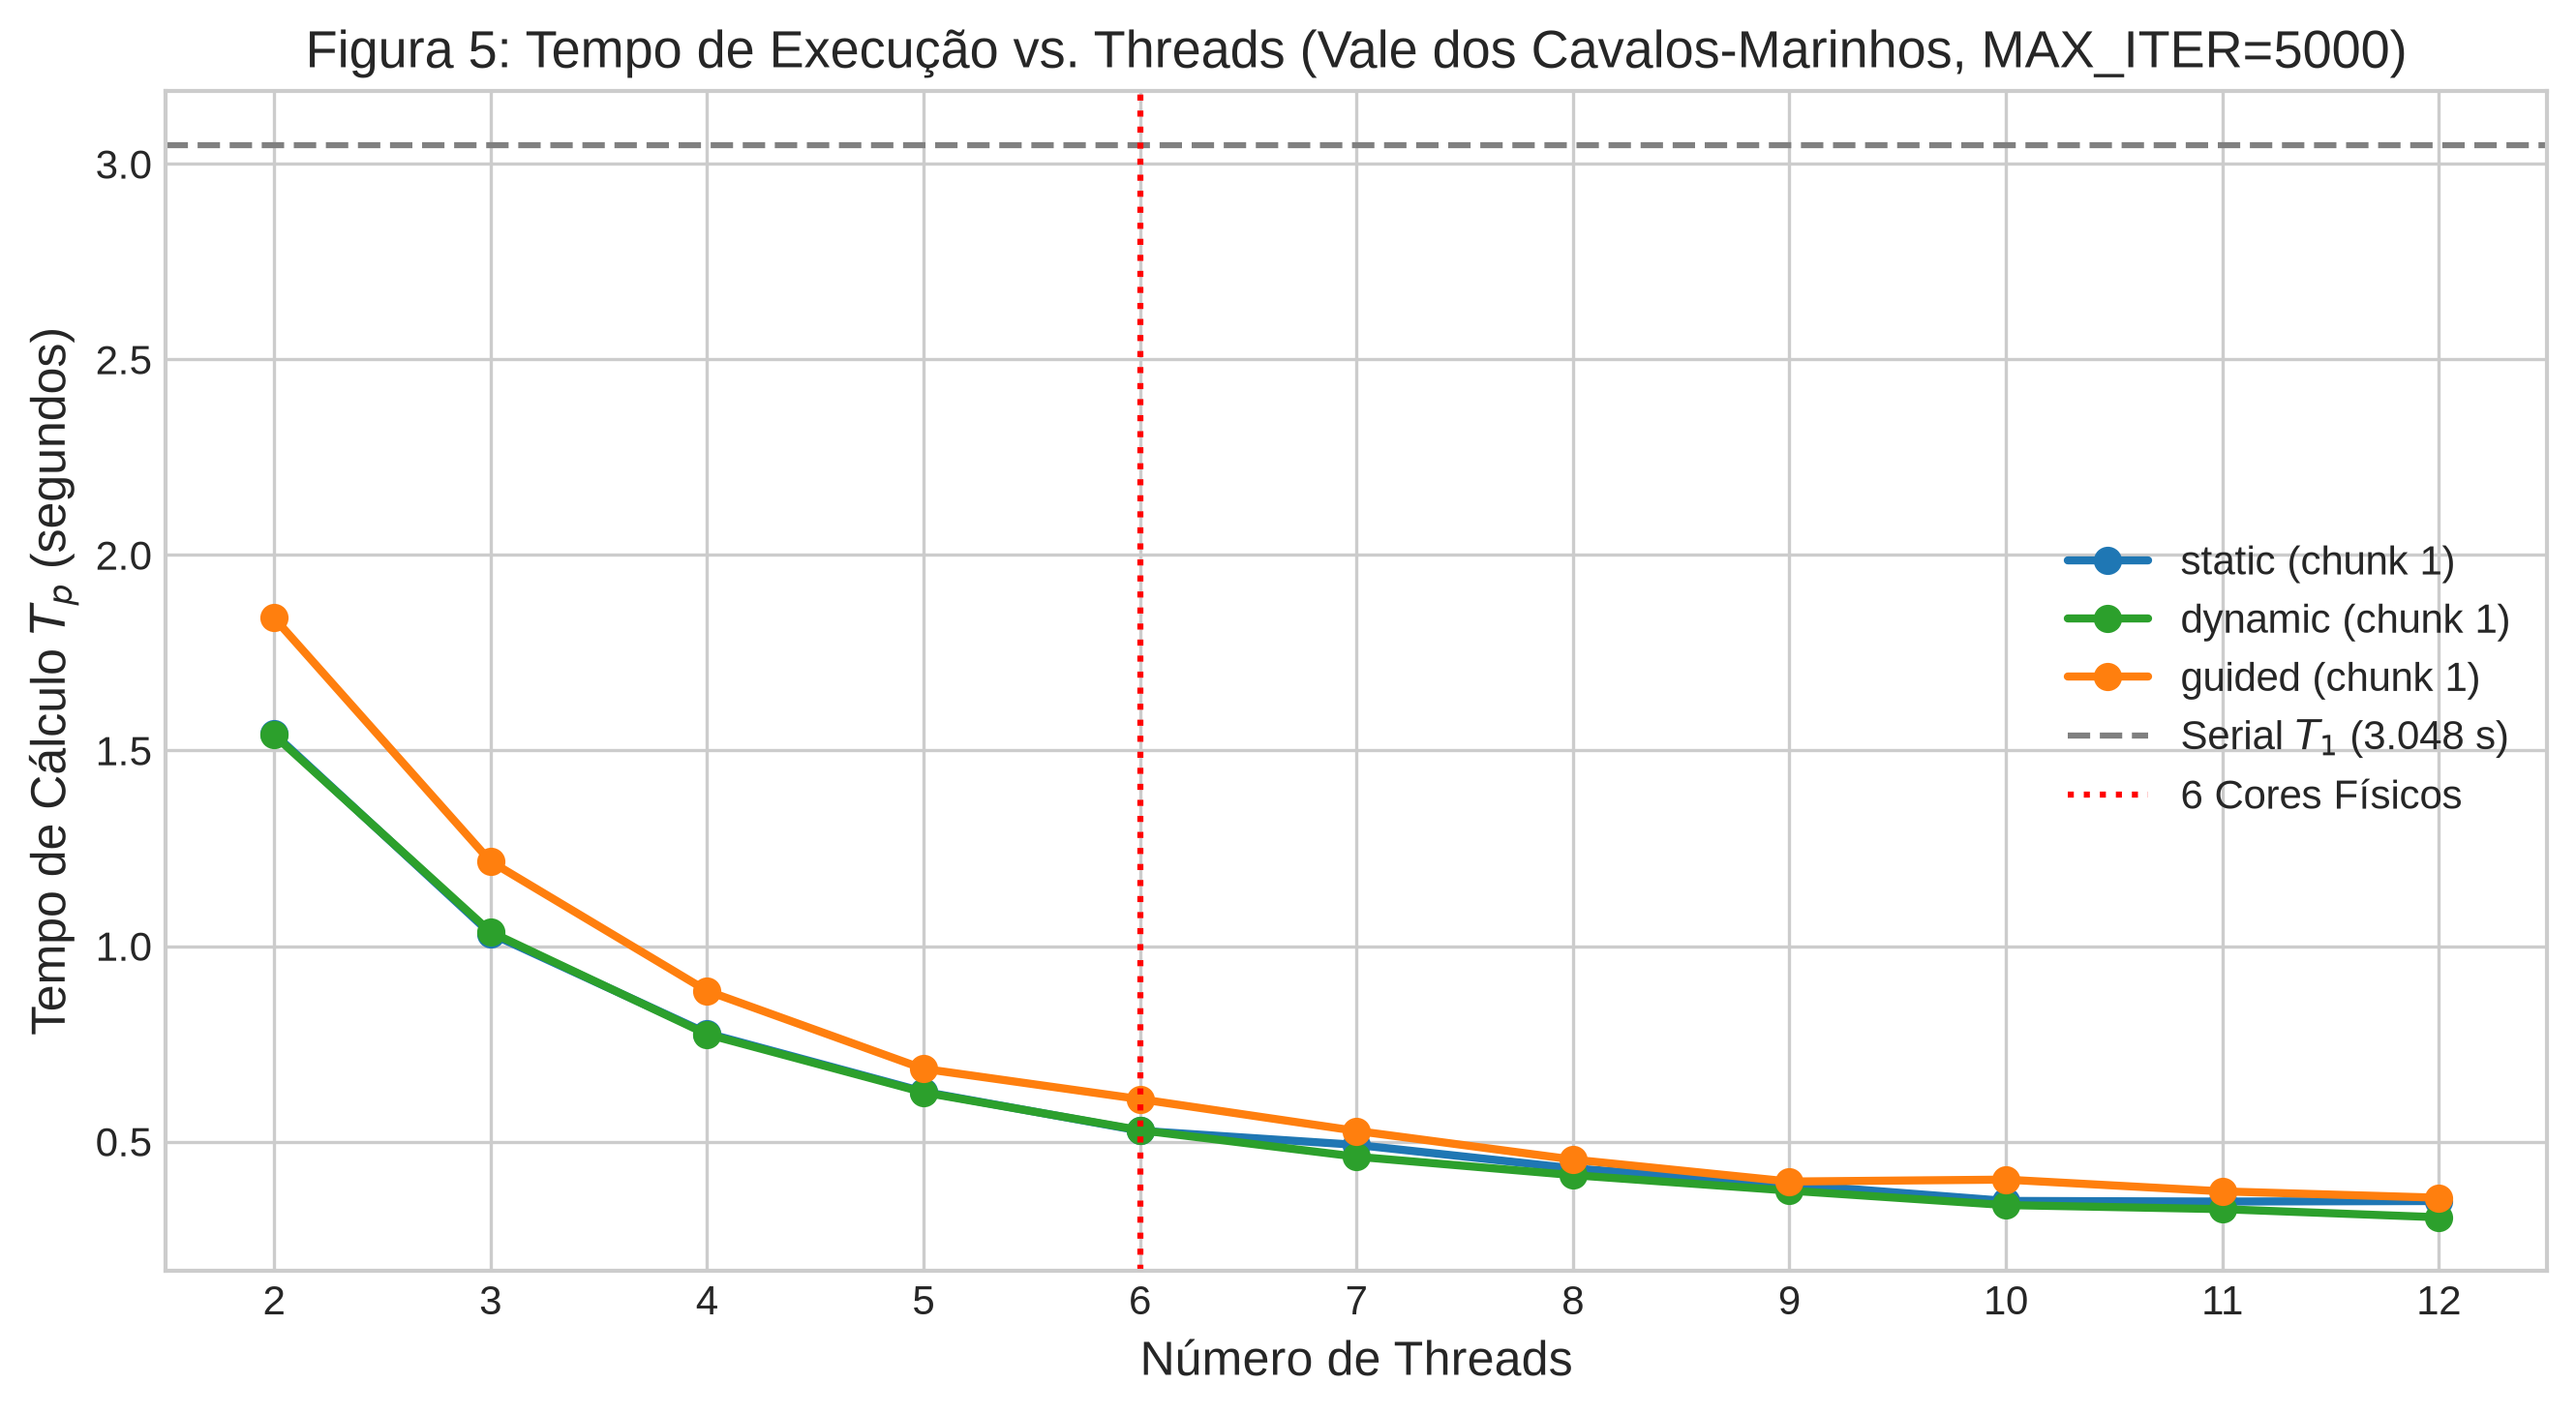

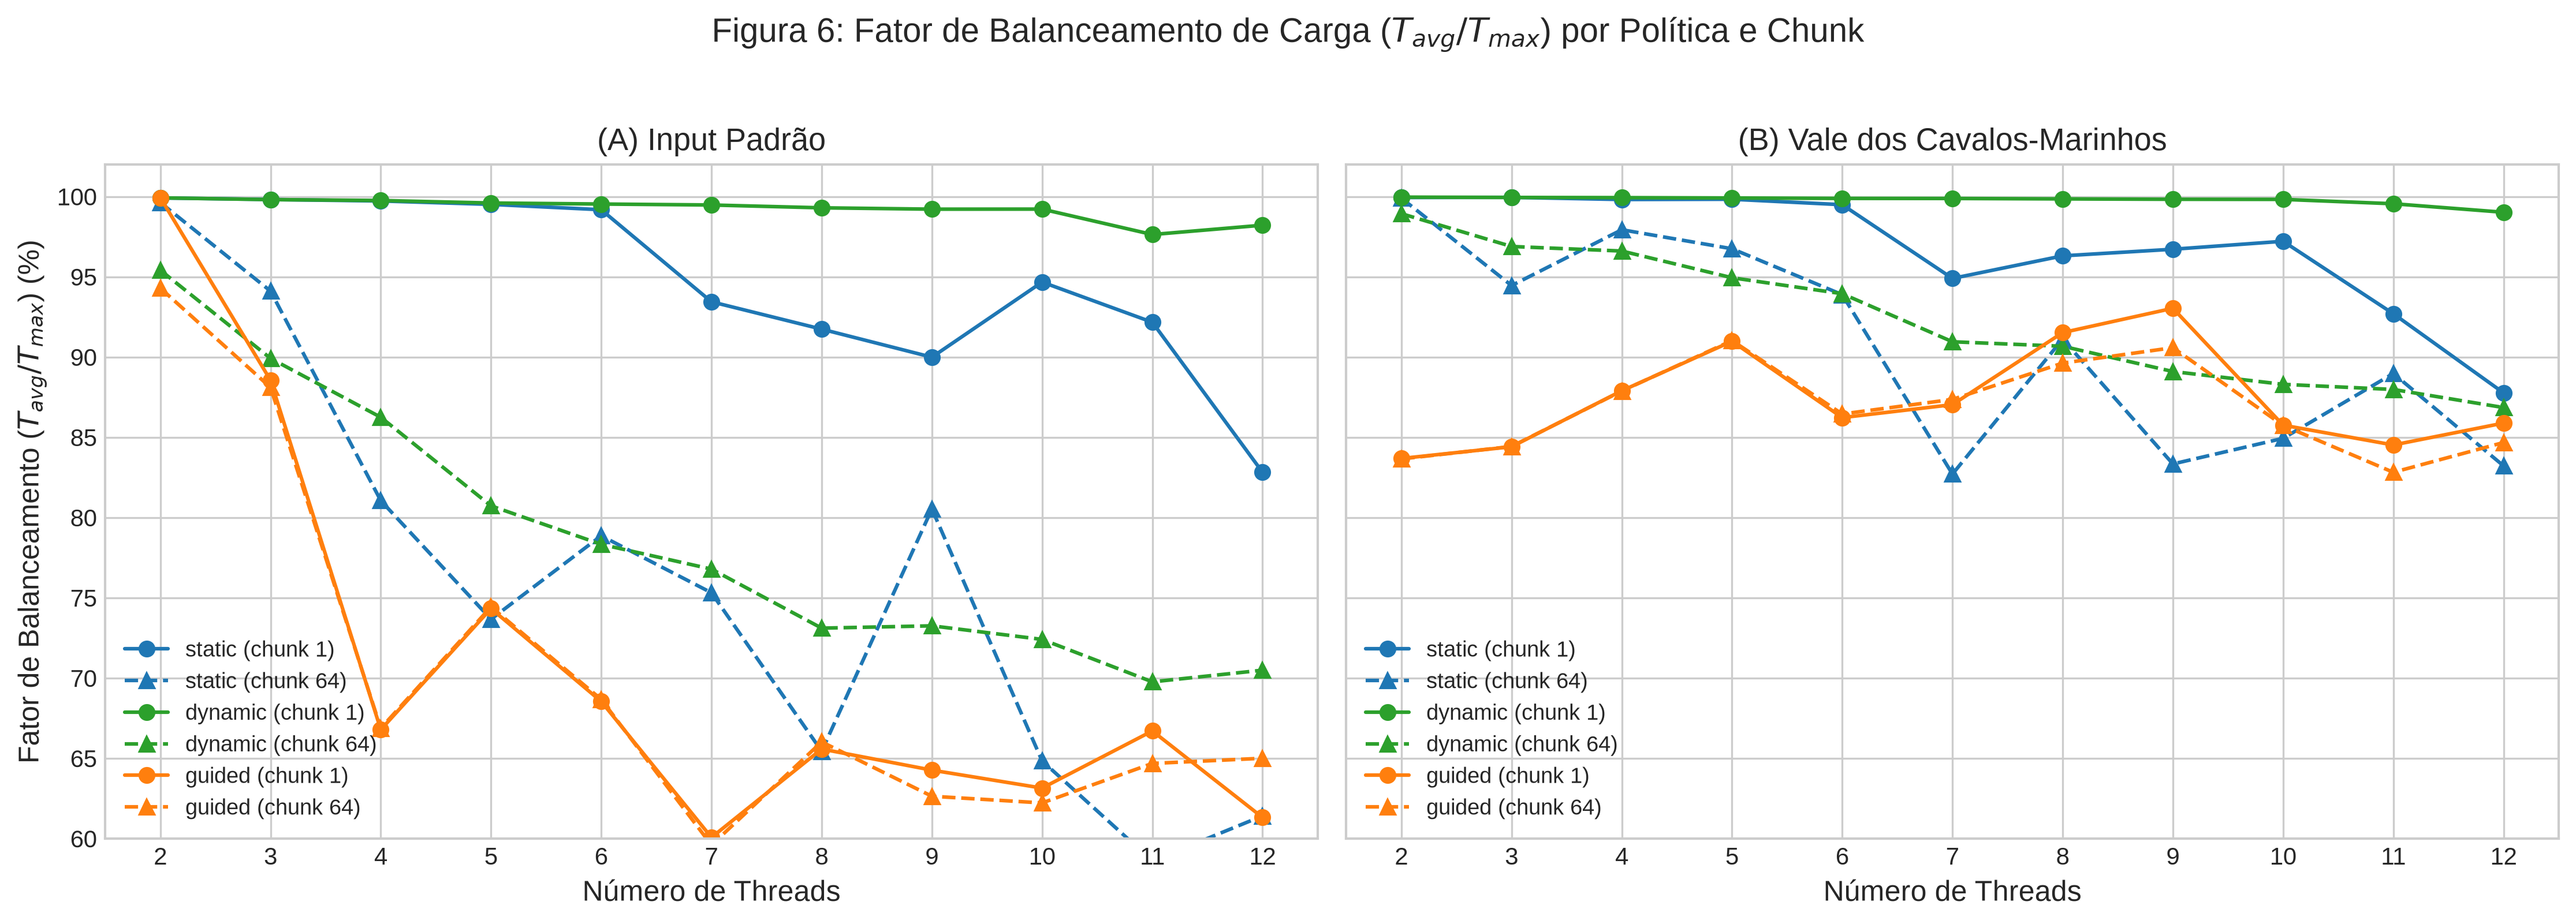

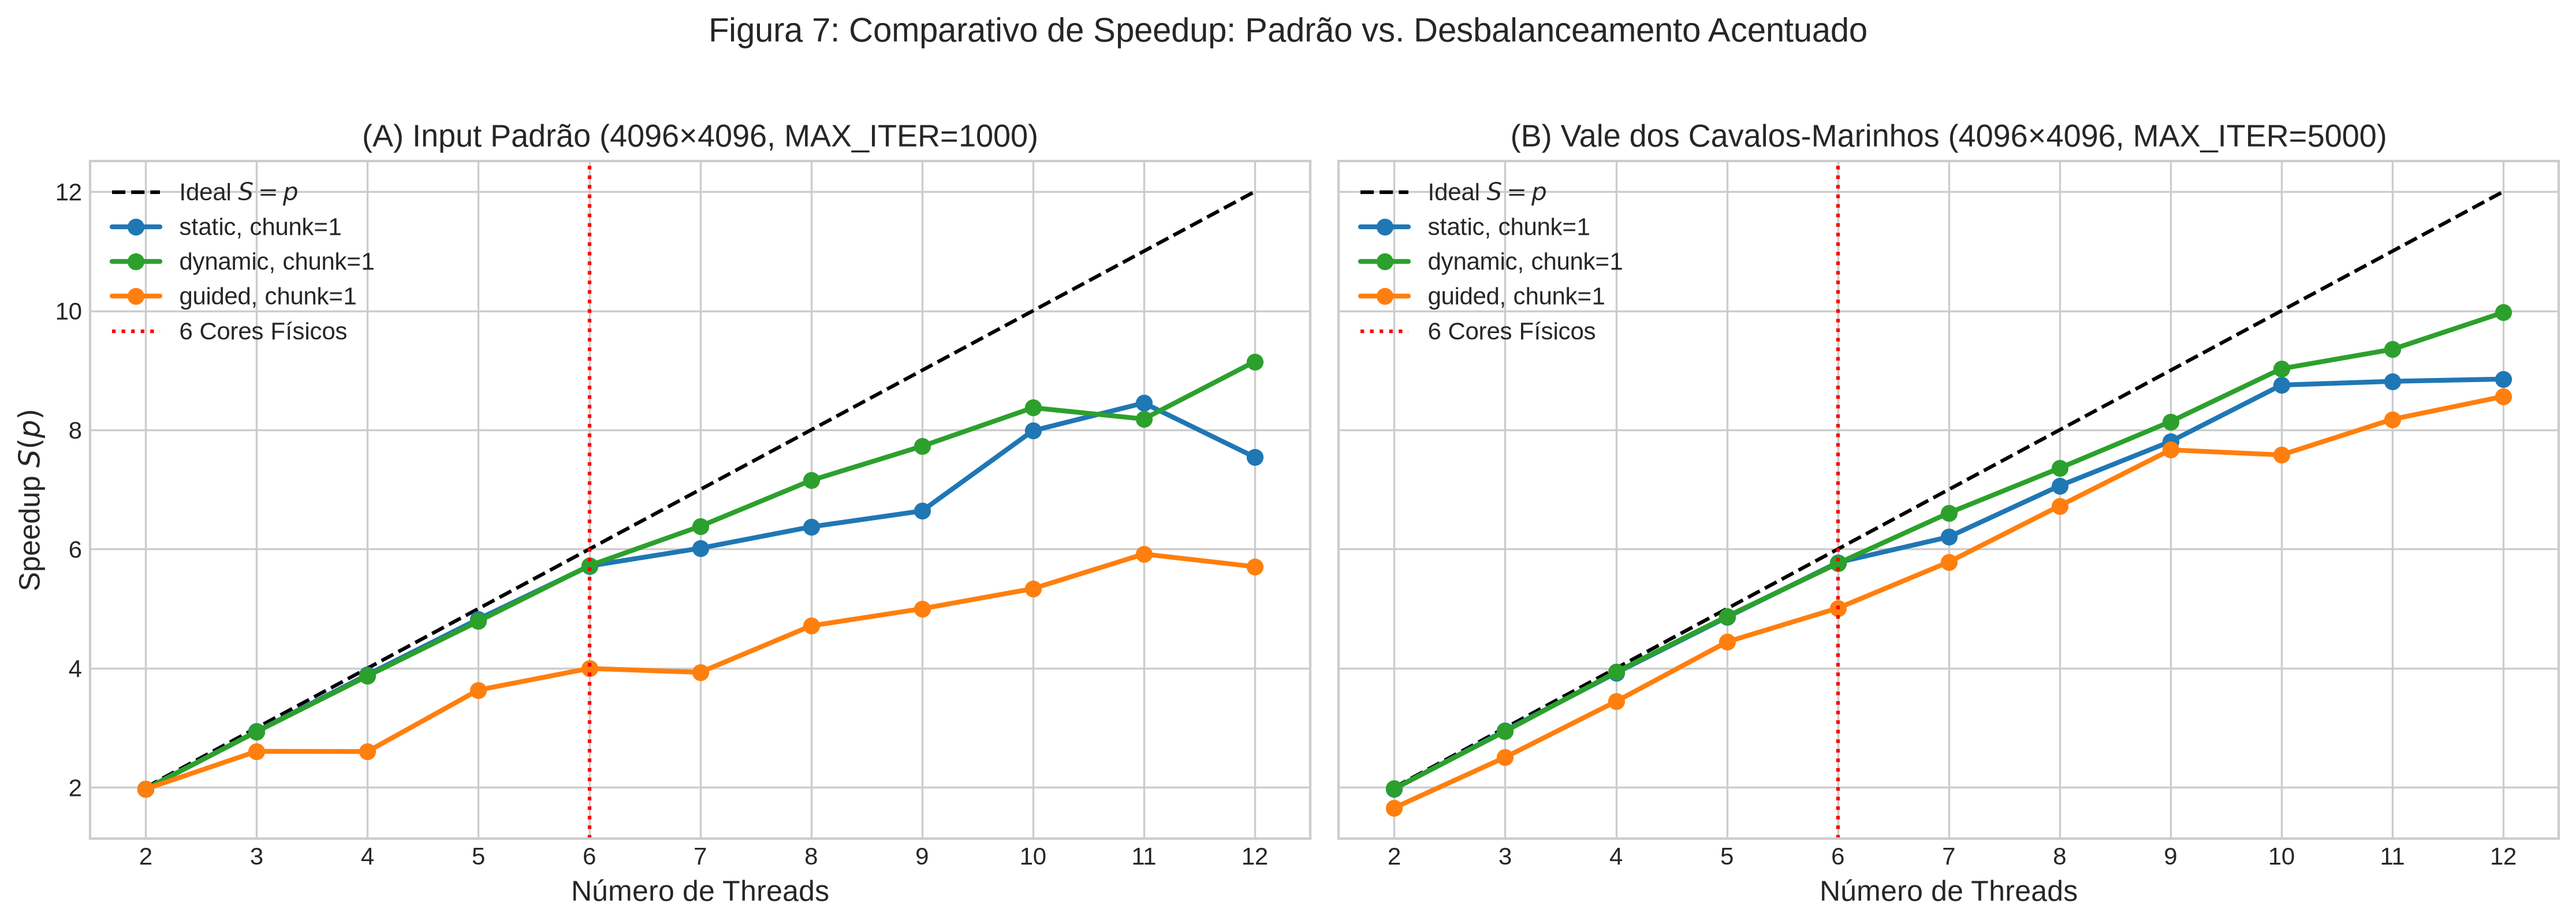

In [17]:
# Figura 5: Tempo de Execução Seahorse
plt.figure(figsize=(9, 5))
for sched in ['static', 'dynamic', 'guided']:
    sub = agg_seahorse[(agg_seahorse['escalonamento'] == sched) & (agg_seahorse['chunk'] == 1)]
    plt.plot(sub['threads'], sub['tp_mean'], marker='o', linewidth=2,
             color=cores_sched[sched], label=f'{sched} (chunk 1)')

t1_ref_s = agg_seahorse['t1_mean'].mean()
plt.axhline(y=t1_ref_s, color='gray', linestyle='--', label=f'Serial $T_1$ ({t1_ref_s:.3f} s)')
plt.axvline(x=6, color='red', linestyle=':', label='6 Cores Físicos')

plt.title('Figura 5: Tempo de Execução vs. Threads (Vale dos Cavalos-Marinhos, MAX_ITER=5000)')
plt.xlabel('Número de Threads')
plt.ylabel('Tempo de Cálculo $T_p$ (segundos)')
plt.xticks(range(2, 13))
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'fig5_tempo_execucao_seahorse.png'))
plt.show()

# Figura 6: Comparativo de Fator de Balanceamento de Carga (Padrão vs Seahorse)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)

for sched in ['static', 'dynamic', 'guided']:
    for chunk in [1, 64]:
        sub_p = agg_padrao[(agg_padrao['escalonamento'] == sched) & (agg_padrao['chunk'] == chunk)]
        sub_s = agg_seahorse[(agg_seahorse['escalonamento'] == sched) & (agg_seahorse['chunk'] == chunk)]
        ls = '-' if chunk == 1 else '--'
        m = 'o' if chunk == 1 else '^'
        
        ax1.plot(sub_p['threads'], sub_p['lbf_mean'] * 100, marker=m, linestyle=ls,
                 color=cores_sched[sched], label=f'{sched} (chunk {chunk})')
        ax2.plot(sub_s['threads'], sub_s['lbf_mean'] * 100, marker=m, linestyle=ls,
                 color=cores_sched[sched], label=f'{sched} (chunk {chunk})')

ax1.set_title('(A) Input Padrão')
ax1.set_xlabel('Número de Threads')
ax1.set_ylabel('Fator de Balanceamento ($T_{avg}/T_{max}$) (%)')
ax1.set_xticks(range(2, 13))
ax1.set_ylim(60, 102)
ax1.legend(loc='lower left', fontsize=9)

ax2.set_title('(B) Vale dos Cavalos-Marinhos')
ax2.set_xlabel('Número de Threads')
ax2.set_xticks(range(2, 13))
ax2.legend(loc='lower left', fontsize=9)

plt.suptitle('Figura 6: Fator de Balanceamento de Carga ($T_{avg}/T_{max}$) por Política e Chunk', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'fig6_balanceamento_carga_comparativo.png'))
plt.show()

# Figura 7: Comparativo de Speedup Padrão vs Seahorse
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
th_range = np.arange(2, 13)
ax1.plot(th_range, th_range, color='black', linestyle='--', label='Ideal $S=p$')
ax2.plot(th_range, th_range, color='black', linestyle='--', label='Ideal $S=p$')

for sched in ['static', 'dynamic', 'guided']:
    sub_p = agg_padrao[(agg_padrao['escalonamento'] == sched) & (agg_padrao['chunk'] == 1)]
    sub_s = agg_seahorse[(agg_seahorse['escalonamento'] == sched) & (agg_seahorse['chunk'] == 1)]
    
    ax1.plot(sub_p['threads'], sub_p['speedup_mean'], marker='o', linewidth=2,
             color=cores_sched[sched], label=f'{sched}, chunk=1')
    ax2.plot(sub_s['threads'], sub_s['speedup_mean'], marker='o', linewidth=2,
             color=cores_sched[sched], label=f'{sched}, chunk=1')

ax1.axvline(x=6, color='red', linestyle=':', label='6 Cores Físicos')
ax2.axvline(x=6, color='red', linestyle=':', label='6 Cores Físicos')

ax1.set_title('(A) Input Padrão (4096×4096, MAX_ITER=1000)')
ax1.set_xlabel('Número de Threads')
ax1.set_ylabel('Speedup $S(p)$')
ax1.set_xticks(range(2, 13))
ax1.legend(loc='upper left')

ax2.set_title('(B) Vale dos Cavalos-Marinhos (4096×4096, MAX_ITER=5000)')
ax2.set_xlabel('Número de Threads')
ax2.set_xticks(range(2, 13))
ax2.legend(loc='upper left')

plt.suptitle('Figura 7: Comparativo de Speedup: Padrão vs. Desbalanceamento Acentuado', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'fig7_speedup_comparativo_padrao_seahorse.png'))
plt.show()


#### Comparativo Completo de Políticas em 12 Threads
A tabela abaixo compara diretamente o tempo de execução, speedup e fator de balanceamento para todas as combinações de política e chunk no hardware saturado (12 threads).


In [11]:
p12 = agg_padrao[agg_padrao['threads'] == 12]
s12 = agg_seahorse[agg_seahorse['threads'] == 12]

comp_12 = pd.merge(
    p12[['escalonamento', 'chunk', 'tp_mean', 'speedup_mean', 'lbf_mean']],
    s12[['escalonamento', 'chunk', 'tp_mean', 'speedup_mean', 'lbf_mean']],
    on=['escalonamento', 'chunk'],
    suffixes=('_padrao', '_seahorse')
)

tabela_comp12 = pd.DataFrame({
    'Política': comp_12['escalonamento'],
    'Chunk': comp_12['chunk'],
    'Tp Padrão (s)': comp_12['tp_mean_padrao'].apply(lambda x: f"{x:.4f}"),
    'Speedup Padrão': comp_12['speedup_mean_padrao'].apply(lambda x: f"{x:.2f}x"),
    'LBF Padrão': (comp_12['lbf_mean_padrao'] * 100).apply(lambda x: f"{x:.1f}%"),
    'Tp Seahorse (s)': comp_12['tp_mean_seahorse'].apply(lambda x: f"{x:.4f}"),
    'Speedup Seahorse': comp_12['speedup_mean_seahorse'].apply(lambda x: f"{x:.2f}x"),
    'LBF Seahorse': (comp_12['lbf_mean_seahorse'] * 100).apply(lambda x: f"{x:.1f}%")
})

tabela_comp12.to_markdown(os.path.join(TABLES_DIR, "tabela_comparativo_politicas_12threads.md"), index=False)
display(tabela_comp12)


,Política,Chunk,Tp Padrão (s),Speedup Padrão,LBF Padrão,Tp Seahorse (s),Speedup Seahorse,LBF Seahorse
0,dynamic,1,0.0463,9.15x,98.2%,0.3065,9.97x,99.0%
1,dynamic,16,0.0554,7.70x,88.0%,0.3378,9.11x,96.5%
2,dynamic,64,0.0644,6.54x,70.5%,0.3484,8.77x,86.9%
3,guided,1,0.0752,5.71x,61.3%,0.3565,8.56x,85.9%
4,guided,16,0.0692,6.11x,62.9%,0.3403,8.96x,88.6%
5,guided,64,0.0667,6.31x,65.0%,0.3552,8.62x,84.7%
6,static,1,0.0570,7.54x,82.8%,0.3480,8.85x,87.8%
7,static,16,0.0568,7.51x,79.4%,0.3476,8.85x,86.4%
8,static,64,0.0700,6.05x,61.4%,0.3572,8.55x,83.2%


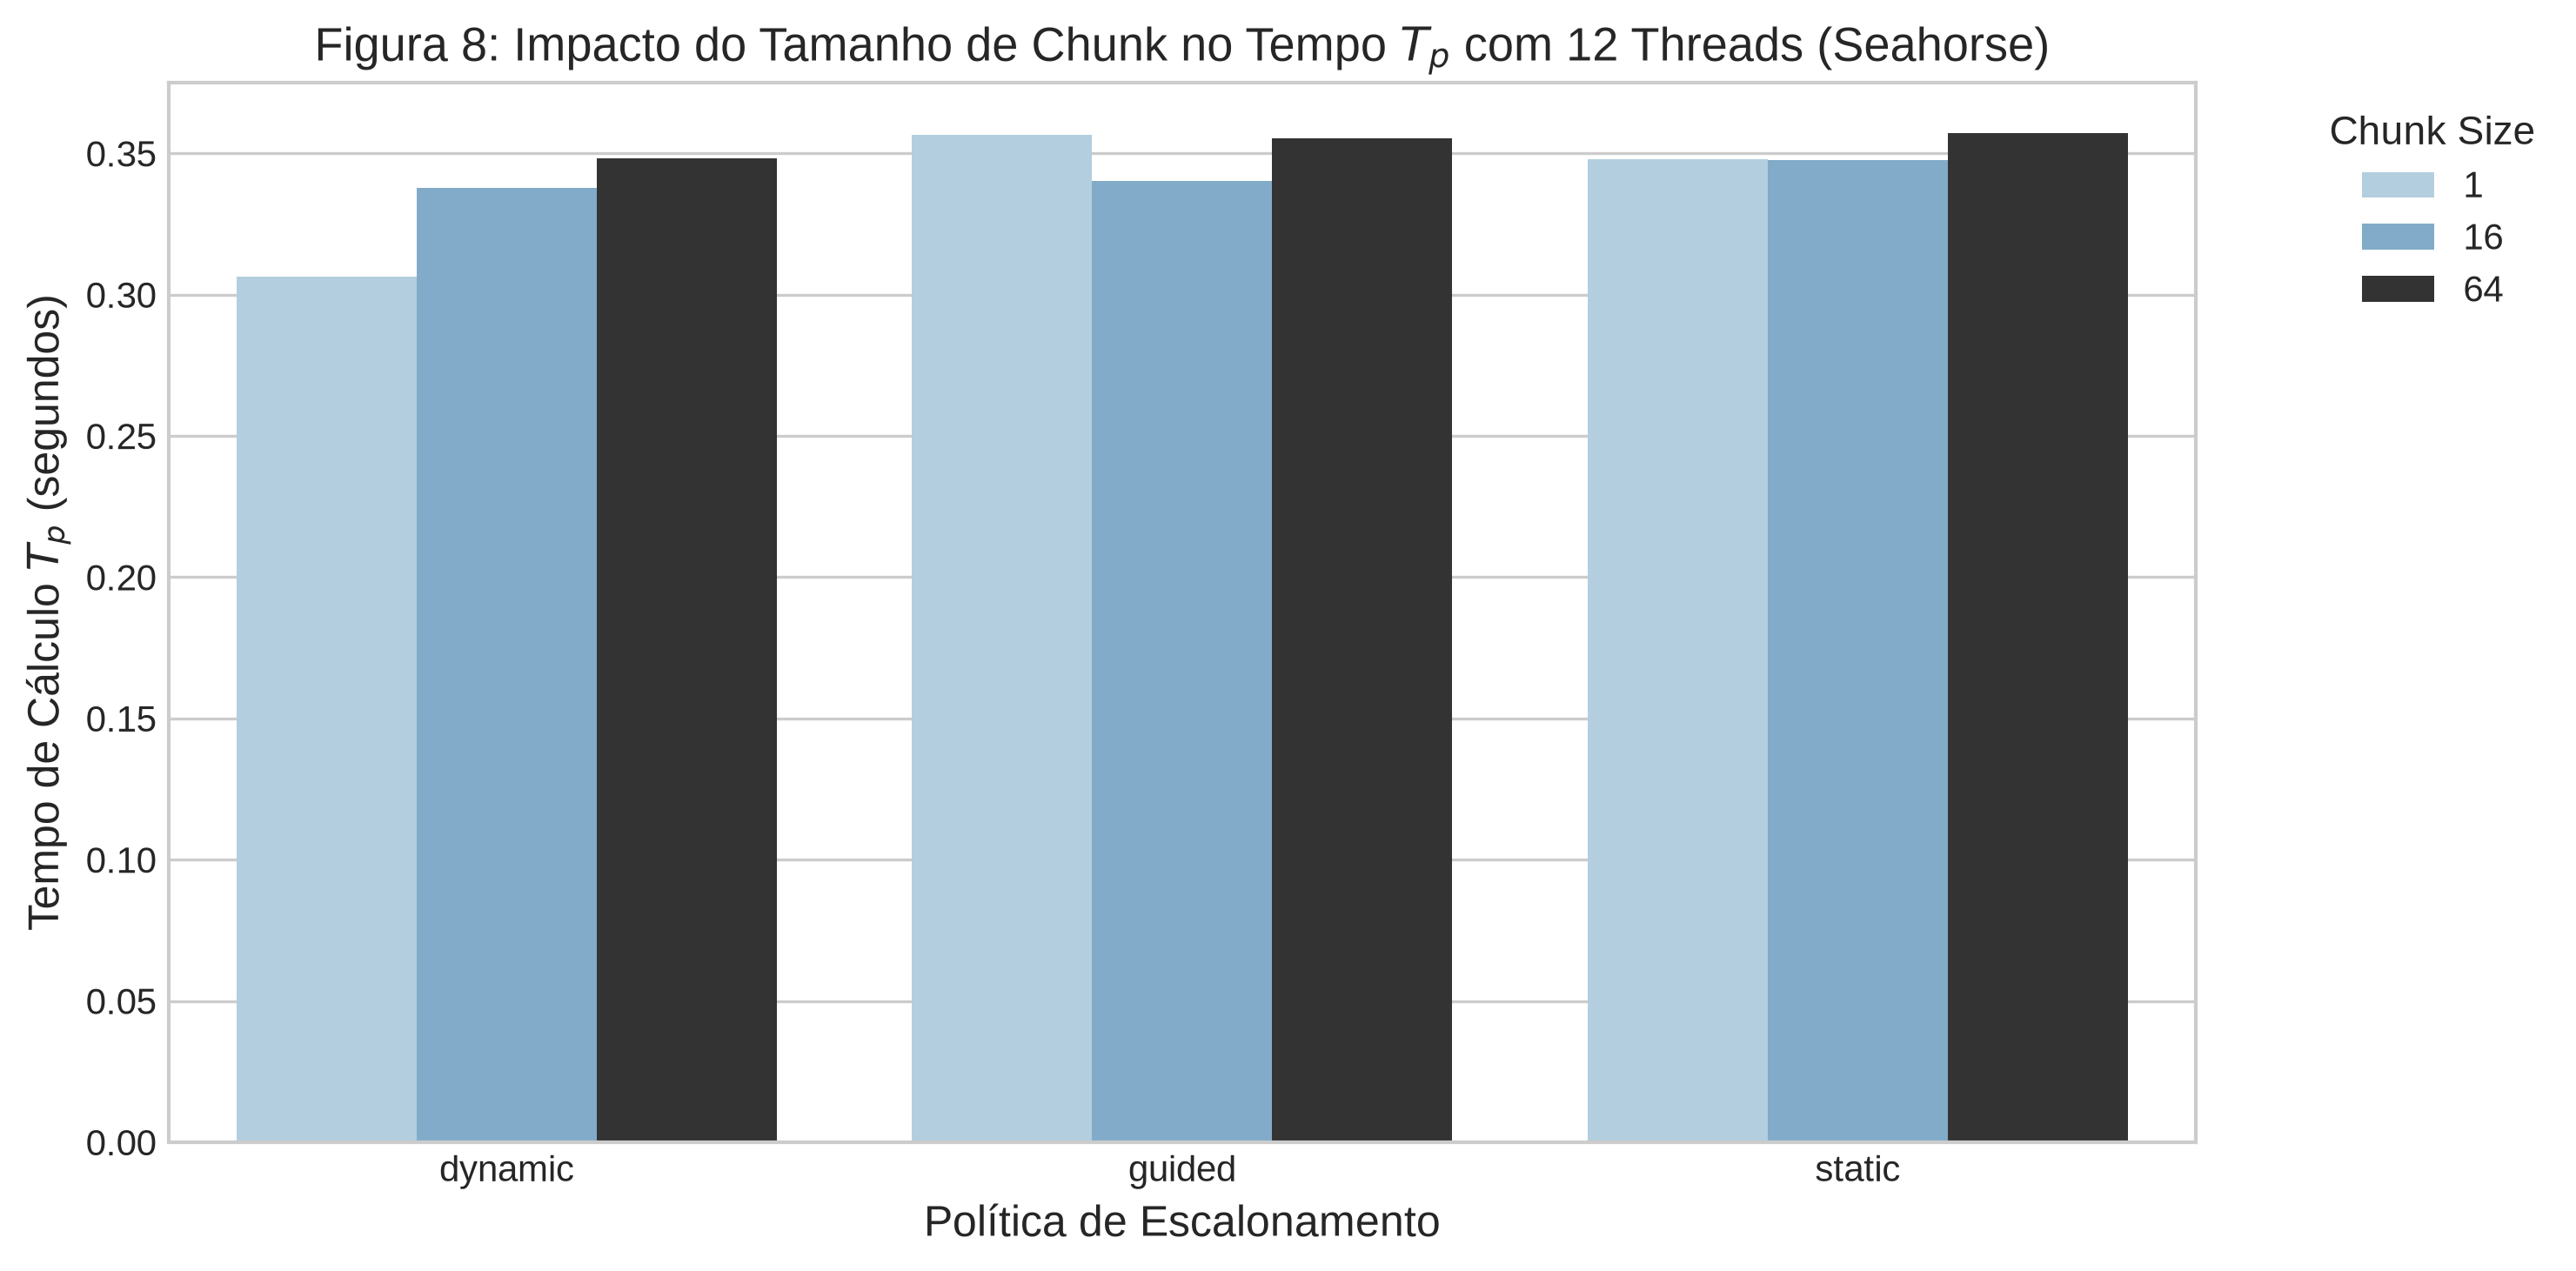

In [12]:
# Figura 8: Impacto do Tamanho de Chunk em 12 Threads no Seahorse
plt.figure(figsize=(10, 5))  # Ligeiramente mais largo para acomodar a legenda externa
sub_s12 = agg_seahorse[agg_seahorse['threads'] == 12]
sns.barplot(data=sub_s12, x='escalonamento', y='tp_mean', hue='chunk', palette='Blues_d')
plt.title('Figura 8: Impacto do Tamanho de Chunk no Tempo $T_p$ com 12 Threads (Seahorse)')
plt.xlabel('Política de Escalonamento')
plt.ylabel('Tempo de Cálculo $T_p$ (segundos)')

# Posiciona a legenda fora, alinhada ao topo da direita
plt.legend(title='Chunk Size', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'fig8_impacto_chunk_seahorse_12threads.png'), bbox_inches='tight')
plt.show()

### 3.5. Análise de Escalabilidade Fraca (Weak Scaling) e Lei de Gustafson

Na escalabilidade fraca, o volume de trabalho cresce proporcionalmente ao número de unidades de processamento ($N \propto p$).
No benchmark avaliamos os casos:
* **$4096 \times 4096$ pixels ($16.7$ Mpx):** executado com **2 threads**.
* **$8192 \times 8192$ pixels ($67.1$ Mpx - 4× carga):** executado com **8 threads** (4× processamento).
* **$16384 \times 16384$ pixels ($268.4$ Mpx - 16× carga):** executado com **12 threads** (limite físico do processador, onde a carga teórica demandaria 32 threads).


,Modo,Resolução,Threads,Configuração,T1 Médio (s),Tp Médio (s),Desvio (s),Speedup,Eficiência (%),LBF (%)
0,Padrão,4096×4096,2,"dynamic, 1",0.4119,0.2107,0.0007,1.95x,97.7%,99.91%
1,Padrão,8192×8192,8,"dynamic, 1",1.6612,0.2338,0.0017,7.11x,88.8%,99.69%
2,Padrão,16384×16384,12,"dynamic, 1",6.5777,0.7041,0.0115,9.34x,77.9%,99.78%
3,Cavalos-Marinhos,4096×4096,2,"dynamic, 1",3.0169,1.5274,0.0065,1.98x,98.8%,99.97%
4,Cavalos-Marinhos,8192×8192,8,"dynamic, 1",12.0197,1.6387,0.0039,7.33x,91.7%,99.92%
5,Cavalos-Marinhos,16384×16384,12,"dynamic, 1",47.7029,4.7300,0.2799,10.11x,84.2%,99.94%


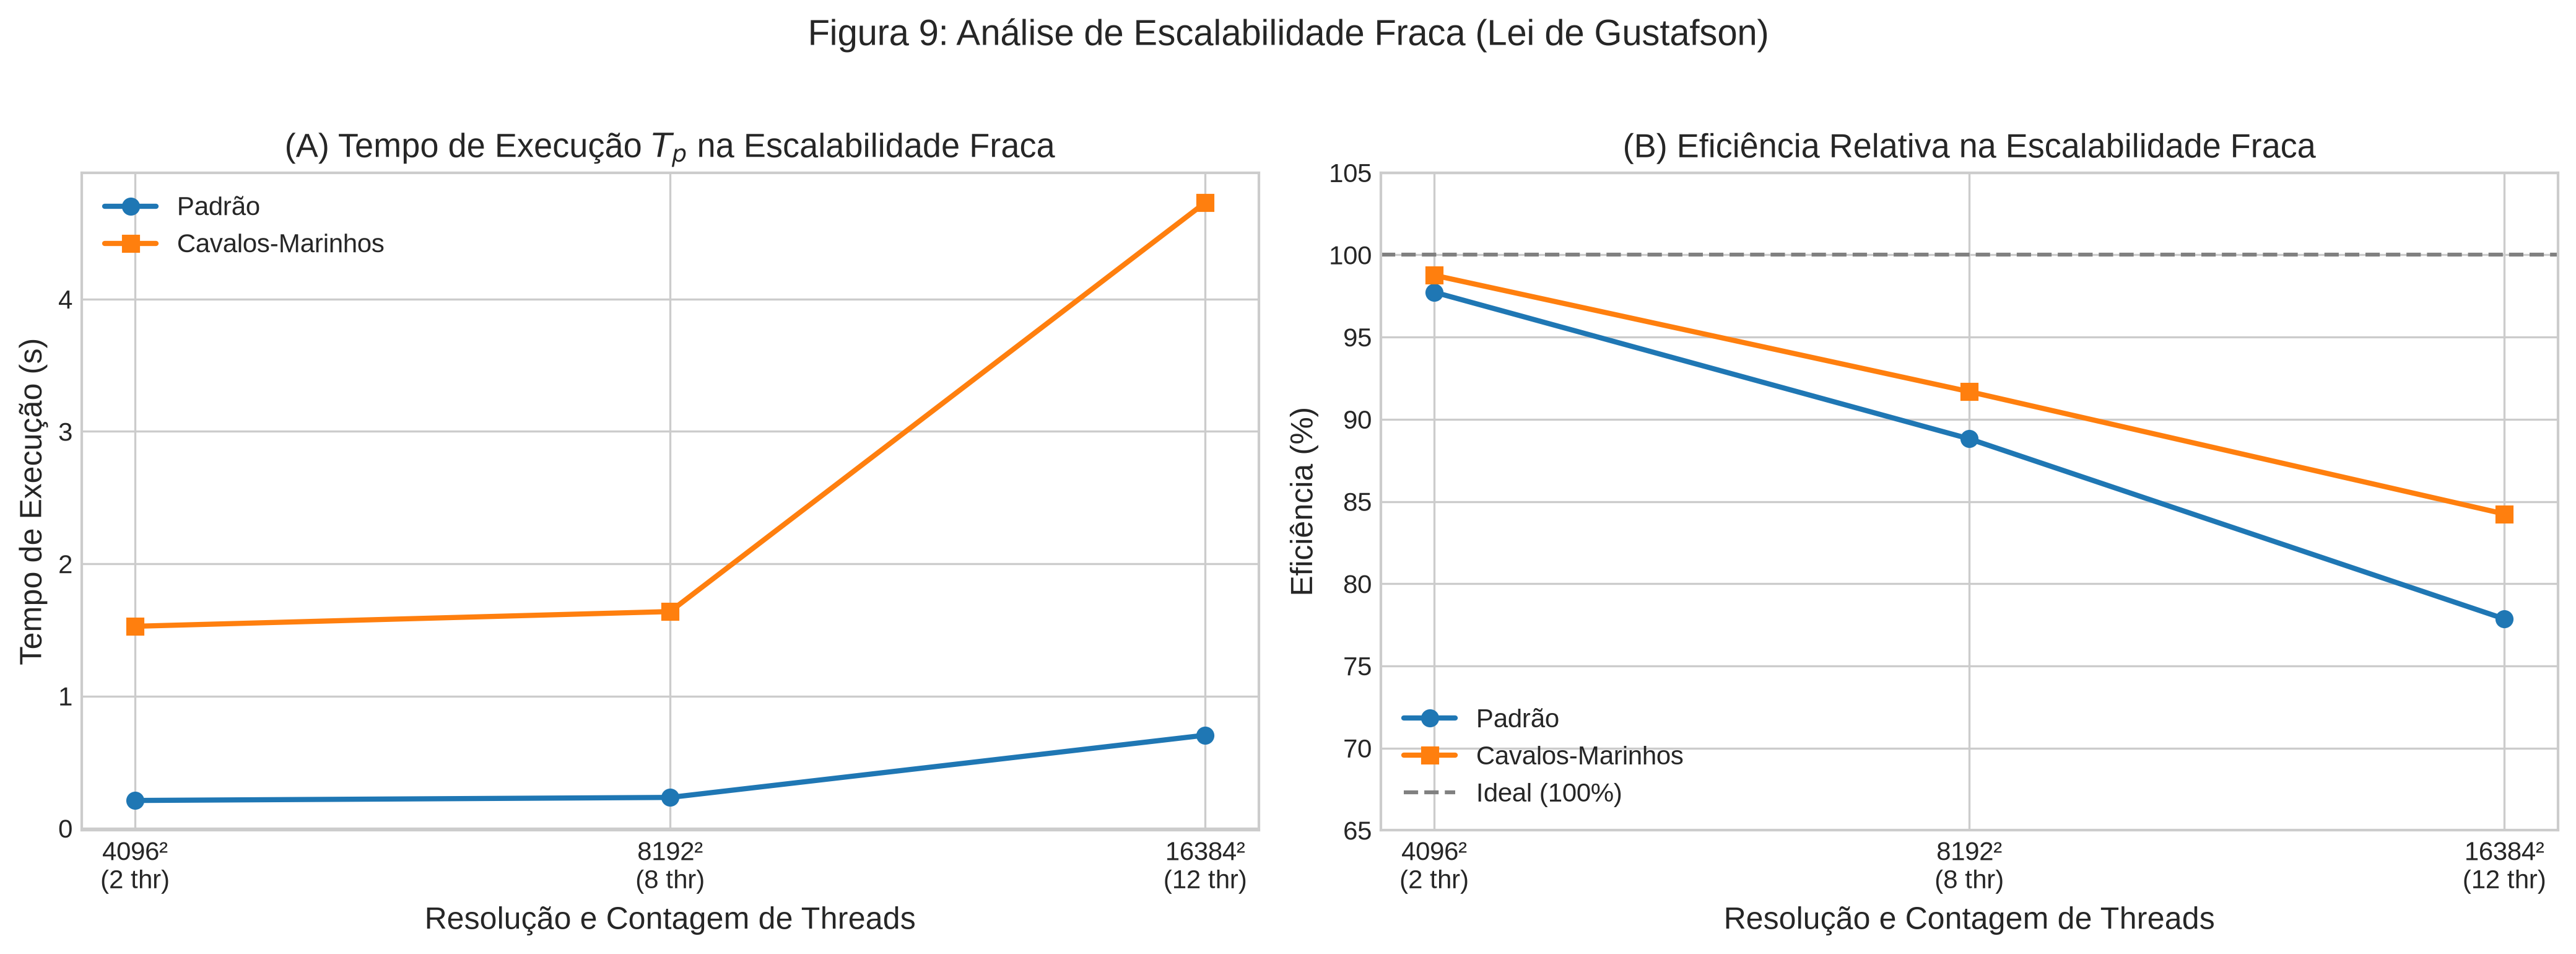

In [13]:
# Tabela de Escalabilidade Fraca
fraca_agg = df_fraca.groupby(['modo', 'largura', 'threads', 'escalonamento', 'chunk']).agg(
    t1_mean=('t1_s', 'mean'),
    tp_mean=('tp_s', 'mean'),
    tp_std=('tp_s', 'std'),
    speedup_mean=('speedup', 'mean'),
    eficiencia_mean=('eficiencia', 'mean'),
    lbf_mean=('fator_balanceamento', 'mean')
).reset_index()

tabela_fraca = pd.DataFrame({
    'Modo': fraca_agg['modo'].replace({'padrao': 'Padrão', 'seahorse': 'Cavalos-Marinhos'}),
    'Resolução': fraca_agg['largura'].apply(lambda x: f"{x}×{x}"),
    'Threads': fraca_agg['threads'],
    'Configuração': fraca_agg.apply(lambda r: f"{r['escalonamento']}, {r['chunk']}", axis=1),
    'T1 Médio (s)': fraca_agg['t1_mean'].apply(lambda x: f"{x:.4f}"),
    'Tp Médio (s)': fraca_agg['tp_mean'].apply(lambda x: f"{x:.4f}"),
    'Desvio (s)': fraca_agg['tp_std'].apply(lambda x: f"{x:.4f}"),
    'Speedup': fraca_agg['speedup_mean'].apply(lambda x: f"{x:.2f}x"),
    'Eficiência (%)': (fraca_agg['eficiencia_mean'] * 100).apply(lambda x: f"{x:.1f}%"),
    'LBF (%)': (fraca_agg['lbf_mean'] * 100).apply(lambda x: f"{x:.2f}%")
})

tabela_fraca.to_markdown(os.path.join(TABLES_DIR, "tabela_escalabilidade_fraca.md"), index=False)
display(tabela_fraca)

# Figura 9: Gráficos de Escalabilidade Fraca
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

fraca_p = fraca_agg[fraca_agg['modo'] == 'padrao']
fraca_s = fraca_agg[fraca_agg['modo'] == 'seahorse']
x_ticks = [f"{w}²\n({t} thr)" for w, t in zip(fraca_p['largura'], fraca_p['threads'])]

# Subplot 1: Tempo de Execução na Escalabilidade Fraca
ax1.plot(range(len(fraca_p)), fraca_p['tp_mean'], marker='o', linewidth=2, color='#1f77b4', label='Padrão')
ax1.plot(range(len(fraca_s)), fraca_s['tp_mean'], marker='s', linewidth=2, color='#ff7f0e', label='Cavalos-Marinhos')
ax1.set_title('(A) Tempo de Execução $T_p$ na Escalabilidade Fraca')
ax1.set_xlabel('Resolução e Contagem de Threads')
ax1.set_ylabel('Tempo de Execução (s)')
ax1.set_xticks(range(len(fraca_p)))
ax1.set_xticklabels(x_ticks)
ax1.legend()

# Subplot 2: Eficiência Relativa
ax2.plot(range(len(fraca_p)), fraca_p['eficiencia_mean'] * 100, marker='o', linewidth=2, color='#1f77b4', label='Padrão')
ax2.plot(range(len(fraca_s)), fraca_s['eficiencia_mean'] * 100, marker='s', linewidth=2, color='#ff7f0e', label='Cavalos-Marinhos')
ax2.axhline(y=100, color='gray', linestyle='--', label='Ideal (100%)')
ax2.set_title('(B) Eficiência Relativa na Escalabilidade Fraca')
ax2.set_xlabel('Resolução e Contagem de Threads')
ax2.set_ylabel('Eficiência (%)')
ax2.set_xticks(range(len(fraca_p)))
ax2.set_xticklabels(x_ticks)
ax2.set_ylim(65, 105)
ax2.legend()

plt.suptitle('Figura 9: Análise de Escalabilidade Fraca (Lei de Gustafson)', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'fig9_escalabilidade_fraca.png'))
plt.show()


### 3.6. Análise de Trade-off: Por que chunk=1 é superior e quais configurações compensam?

#### 1. Por que o Speedup e o Fator de Balanceamento são claramente maiores com `chunk = 1`?
A superioridade empírica do `chunk = 1` decorre da interação entre a **geometria do fractal** e a **granularidade do paralelismo em OpenMP**:
* **O laço paralelizado é o externo (`for py = 0 ... limit_y`):** Um chunk de tamanho $1$ **não é $1$ pixel, mas sim $1$ linha horizontal completa de $4096$ pixels**.
* **Heterogeneidade Vertical da Carga:** As linhas horizontais que cruzam o bulbo central do fractal contêm milhares de pixels que executam até $5000$ iterações, enquanto as linhas das bordas externas escapam em poucas iterações ($< 10$).
* **O Efeito Prejudicial de Chunks Grandes ($64$ linhas):** Com `chunk=64`, uma thread recebe um bloco contíguo de $64$ linhas no centro do fractal, acumulando centenas de milhões de iterações, enquanto threads alocadas nas bordas terminam rapidamente e ficam ociosas aguardando na barreira de sincronização. Isso derruba o Fator de Balanceamento para $83.2\%$ no Seahorse e $61.4\%$ no Padrão.
* **Amortização do Overhead com `chunk=1`:** Uma única linha de $4096$ pixels contém trabalho computacional expressivo (entre dezenas de milhares e mais de $20$ milhões de operações em ponto flutuante). O custo de uma operação atômica de incremento na fila compartilhada do OpenMP é de frações de microssegundo, sendo **completamente diluído** pela massa computacional da linha. Assim, `dynamic, 1` obtém granularidade fina sem sofrer com sobrecarga de sincronização, alcançando **$99.02\%$ de balanceamento** e **$9.97\times$ de speedup**.

---

#### 2. Existe outra configuração que compense um Speedup/Balanceamento ligeiramente menor?
**Sim!** Em computação de alto desempenho, a configuração com maior speedup bruto nem sempre é a escolha arquitetural ótima em todos os cenários. Duas configurações alternativas destacam-se por oferecer vantagens compensatórias cruciais:

##### A) `static, chunk=1` (Distribuição Cíclica / Round-Robin):
* **Zero Overhead de Sincronização:** Não há fila compartilhada, nem travas atômicas (*locks*) ou tráfego de coerência de cache sobre ponteiros de laço. A partição é calculada matematicamente a priori ($py \equiv tid \pmod p$).
* **Determinismo Absoluto:** A atribuição de linhas a threads é 100% reproduzível, facilitando profiling e auditoria de cache.
* **Superioridade em Núcleos Físicos (2 a 6 threads):** Nos testes com até 6 núcleos físicos, o `static, 1` **superou o `dynamic, 1`** tanto no Padrão (em 3, 4 e 5 threads) quanto no Seahorse (em 3 e 6 threads, atingindo $5.78\times$ vs $5.76\times$), exatamente porque o entrelaçamento cíclico de linhas é suficiente para balancear a carga e economiza todo o overhead de fila!
* **Viabilidade para Memória Distribuída (MPI - Etapa 2):** Em MPI, filas dinâmicas exigem protocolo Mestre-Trabalhador com mensagens de rede contínuas (latência de microssegundos/milissegundos). A distribuição cíclica `static, 1` permite que cada processo MPI calcule suas linhas de forma totalmente autônoma, com **zero comunicação durante o cálculo**.

##### B) `dynamic, chunk=16` (Equilíbrio entre Fila e Balanceamento):
* **Redução de $93.75\%$ no Tráfego da Fila:** Em vez de $4096$ acessos à fila de trabalho, as threads realizam apenas $256$ despachos no total ($16\times$ menos requisições atômicas).
* **Localidade Espacial e Prefetching:** Um bloco de $16$ linhas consecutivas ($65.536$ pixels $= 262$ KB) favorece o mecanismo de *hardware prefetcher* da CPU e escritas contíguas na memória RAM.
* **Excelente Desempenho:** Atinge **$9.11\times$ de speedup** e **$96.45\%$ de balanceamento** em 12 threads no Seahorse — uma perda marginal de apenas $31$ milissegundos frente ao `dynamic, 1`, porém com muito menor contenção de barramento de controle.


,Configuração,Despachos de Fila,Overhead Sincronização,Localidade Espacial,Determinismo,Speedup 6T (Físicos),Speedup 12T (SMT),LBF 12T (%),Vantagens Compensatórias
0,"dynamic, chunk=1",4096 (1/linha),Médio (atômico por linha),Linha única (4096 px),Não-determinístico,5.76x,9.97x,99.0%,Máximo speedup e balanceamento sob concorrênci...
1,"static, chunk=1 (Cíclico)",0 (zero chamadas),Zero (partição estática a priori),Linha única (4096 px),100% Determinístico,5.78x,8.85x,87.8%,Supera dynamic em 6 cores físicos; sem lock co...
2,"dynamic, chunk=16",256 (16x menos),Muito baixo (16x menos contenção),Excelente (blocos de 16 linhas),Não-determinístico,5.73x,9.11x,96.5%,Speedup > 9.1x com 96.5% LBF e redução drástic...
3,"guided, chunk=16",~50-100 (decrescente),Mínimo (chunks adaptativos),"Alta no início, fina no final",Não-determinístico,5.03x,8.96x,88.6%,Combina alto throughput inicial com ajuste fin...
4,"static, chunk=16",0 (zero chamadas),Zero (partição estática a priori),Excelente (blocos contíguos de 16 linhas),100% Determinístico,5.69x,8.85x,86.4%,Excelente localidade e prefetching; bom balanc...


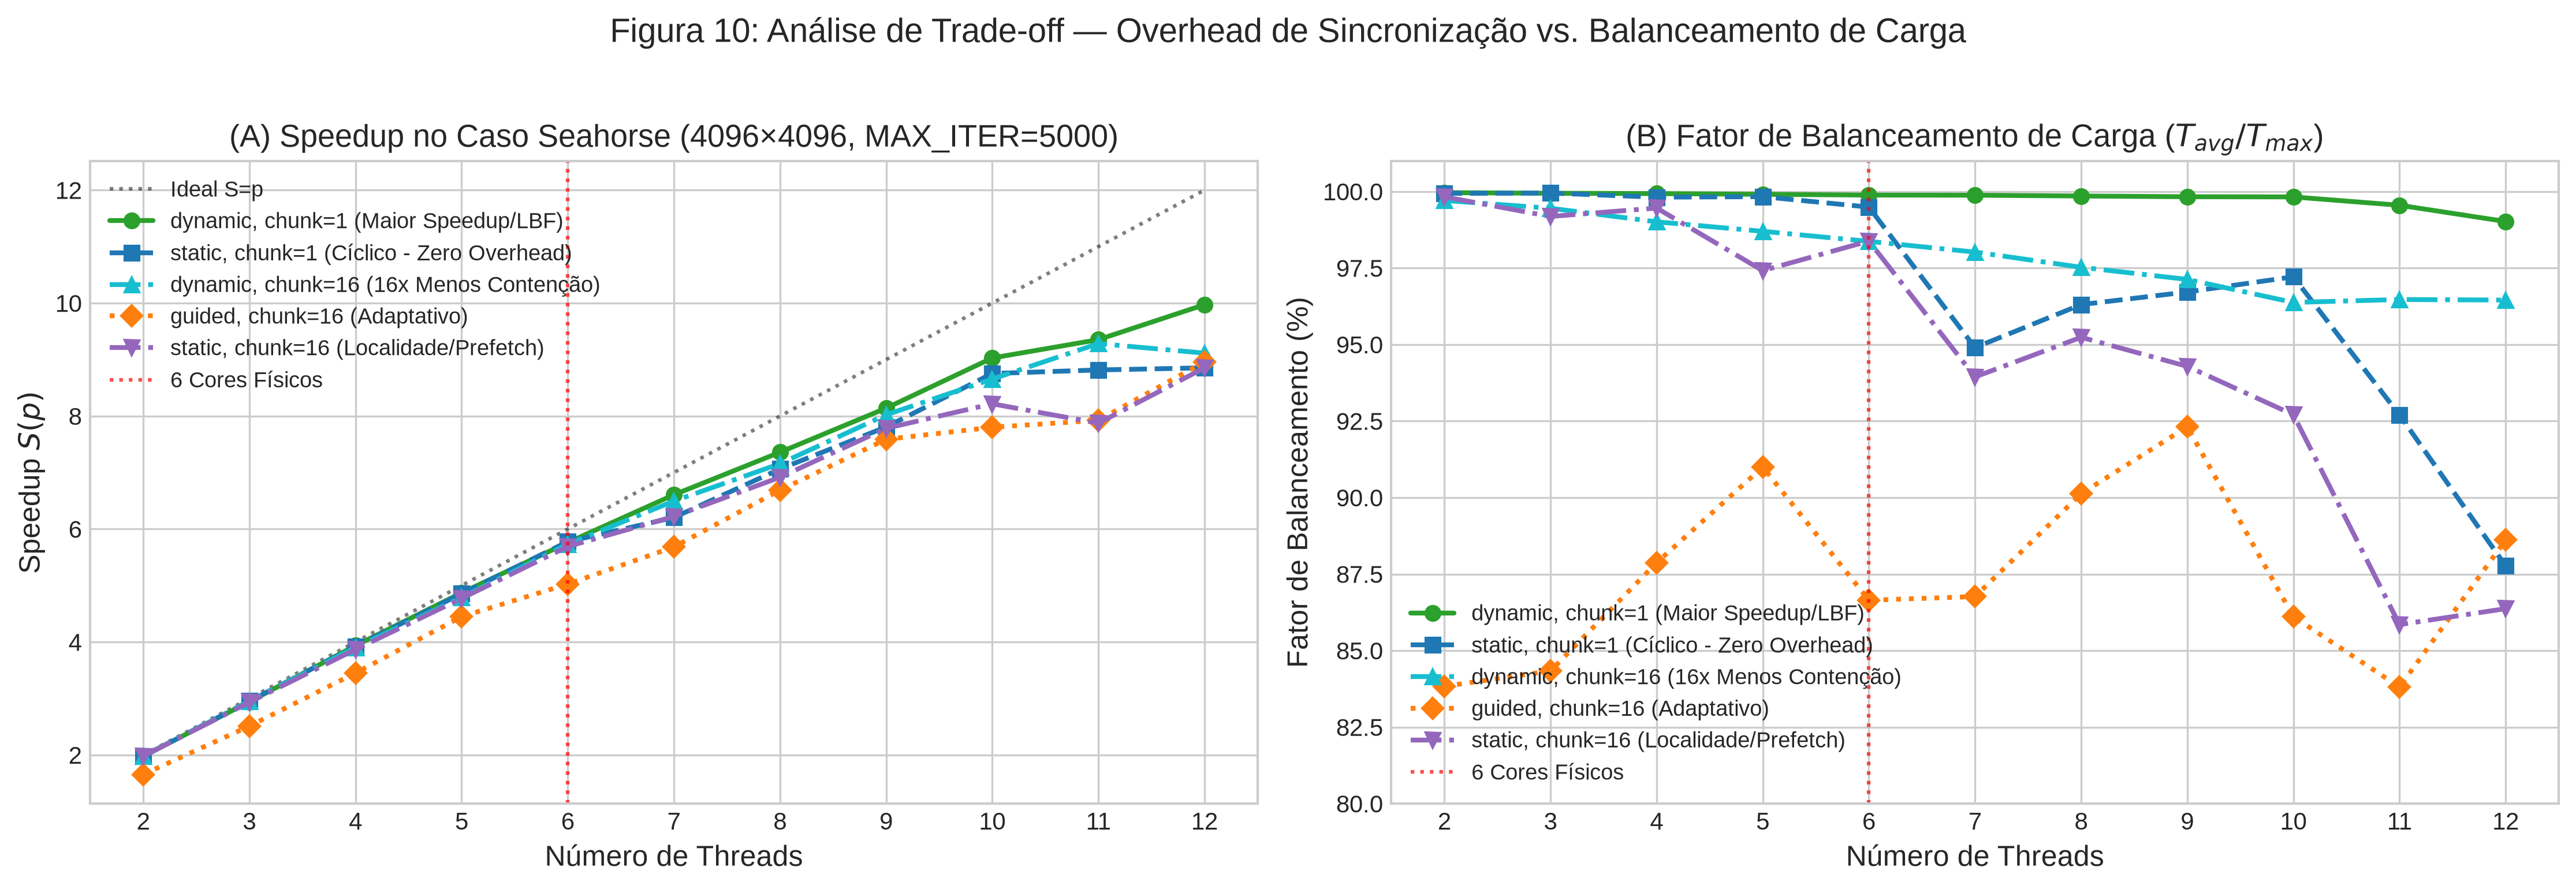

In [14]:
# Tabela de Trade-off entre Políticas e Chunks
df_tradeoff = pd.read_csv(os.path.join(TABLES_DIR, "tabela_tradeoff_configuracoes.csv"))
display(df_tradeoff)

# Figura 10: Gráfico comparativo de Trade-off
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

configs_plot = [
    ('dynamic', 1, '#2ca02c', '-', 'o', 'dynamic, chunk=1 (Maior Speedup/LBF)'),
    ('static', 1, '#1f77b4', '--', 's', 'static, chunk=1 (Cíclico - Zero Overhead)'),
    ('dynamic', 16, '#17becf', '-.', '^', 'dynamic, chunk=16 (16x Menos Contenção)'),
    ('guided', 16, '#ff7f0e', ':', 'D', 'guided, chunk=16 (Adaptativo)'),
    ('static', 16, '#9467bd', '-.', 'v', 'static, chunk=16 (Localidade/Prefetch)')
]

th_range = np.arange(2, 13)
ax1.plot(th_range, th_range, color='black', linestyle=':', alpha=0.5, label='Ideal S=p')
for sched, ch, color, ls, m, lbl in configs_plot:
    sub = agg_seahorse[(agg_seahorse['escalonamento'] == sched) & (agg_seahorse['chunk'] == ch)]
    ax1.plot(sub['threads'], sub['speedup_mean'], color=color, linestyle=ls, marker=m, linewidth=2, label=lbl)

ax1.axvline(x=6, color='red', linestyle=':', alpha=0.7, label='6 Cores Físicos')
ax1.set_title('(A) Speedup no Caso Seahorse (4096×4096, MAX_ITER=5000)')
ax1.set_xlabel('Número de Threads')
ax1.set_ylabel('Speedup $S(p)$')
ax1.set_xticks(range(2, 13))
ax1.legend(loc='upper left', fontsize=9)

for sched, ch, color, ls, m, lbl in configs_plot:
    sub = agg_seahorse[(agg_seahorse['escalonamento'] == sched) & (agg_seahorse['chunk'] == ch)]
    ax2.plot(sub['threads'], sub['lbf_mean'] * 100, color=color, linestyle=ls, marker=m, linewidth=2, label=lbl)

ax2.axvline(x=6, color='red', linestyle=':', alpha=0.7, label='6 Cores Físicos')
ax2.set_title('(B) Fator de Balanceamento de Carga ($T_{avg}/T_{max}$)')
ax2.set_xlabel('Número de Threads')
ax2.set_ylabel('Fator de Balanceamento (%)')
ax2.set_xticks(range(2, 13))
ax2.set_ylim(80, 101)
ax2.legend(loc='lower left', fontsize=9)

plt.suptitle('Figura 10: Análise de Trade-off — Overhead de Sincronização vs. Balanceamento de Carga', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'fig10_tradeoff_configuracoes.png'))
plt.show()


## 4. Discussão Aprofundada dos Resultados

Com base nos dados empíricos obtidos, os seguintes pontos fundamentais devem ser destacados no relatório:

### 4.1. Corretude Numérica e Determinismo
A validação bit a bit via comparação binária direta e hashes criptográficos SHA-256 atesta equivalência matemática estrita ($0$ erros em mais de $16.7$ milhões de pontos avaliados). Por se tratar de um cálculo determinístico em aritmética IEEE 754 de dupla precisão (`double`), o mapeamento linear e a contagem inteira garantem reprodutibilidade perfeita entre execuções seriais e paralelas.

### 4.2. Impacto do Número de Threads: Cores Físicos vs. SMT (Hyper-Threading)
Observa-se um comportamento nítido de duas fases na curva de escalabilidade forte:
1. **Fase Linear / Quase-Ideal ($2$ a $6$ threads):** A CPU possui $6$ núcleos físicos Zen 3. Nessa faixa, cada thread OpenMP é alocada em um núcleo independente, resultando em escalabilidade quase perfeita:
   - Input Padrão: $Speedup = 5.72\times$ em 6 threads (Eficiência de $95.4\%$).
   - Seahorse: $Speedup = 5.78\times$ em 6 threads (Eficiência de $96.3\%$).
2. **Fase de Concorrência SMT ($7$ a $12$ threads):** O acréscimo de threads lógicas compartilha os recursos de execução de hardware (ALUs, FPUs, pipelines de instrução e caches L1/L2) de cada núcleo físico. Embora o speedup continue crescendo até $9.15\times$ (Padrão) e $9.97\times$ (Seahorse), a eficiência cai para $\sim 76\% - 83\%$. Esse ganho adicional ($\\approx 1.7\times$ sobre 6 núcleos) é o teto prático típico do SMT da AMD para algoritmos intensivos em ponto flutuante.

### 4.3. Análise Central de Balanceamento de Carga: Por que o problema é desbalanceado?
O custo de processar um pixel é estritamente proporcional ao seu escape-time:
* Pixels externos ao conjunto escapam em $1$ a $10$ iterações.
* Pixels no interior ou na fronteira fractal executam o teto de iterações ($1000$ no padrão, $5000$ no Seahorse).
Isso cria uma **heterogeneidade de carga extrema** no plano complexo.

**Comportamento das Políticas de Escalonamento:**
* **`static, chunk=64`:** Divide o domínio em blocos contíguos fixos de 64 linhas. No caso Seahorse, uma thread atribuída à faixa central do fractal recebe milhões de iterações a mais que uma thread alocada nas bordas, derrubando o Fator de Balanceamento para $83.2\%$ e o Speedup para $8.55\times$.
* **`dynamic, chunk=1`:** As threads solicitam novas linhas de trabalho à medida que terminam a anterior. Como a granularidade é de uma linha inteira ($4096$ pixels), o custo de sincronização atômica é ínfimo frente ao tempo de cálculo. O Fator de Balanceamento atinge impressionantes **$99.02\%$** e o Speedup atinge **$9.97\times$**.
* **`guided`:** Reduz exponencialmente o tamanho dos blocos. Teve desempenho intermediário, porém inferior ao `dynamic, 1` devido aos blocos iniciais grandes reterem desbalanceamento nas primeiras iterações.

### 4.4. Otimização de Simetria Axial
No input padrão, a região é simétrica em relação ao eixo real ($Im \in [-1.5, 1.5]$). O código implementa o cálculo de apenas metade das linhas ($py < height/2$) e espelha o resultado na metade inferior. Isso reduz o volume computacional bruto pela metade. No caso do Seahorse, a coordenada imaginária não cruza o zero, exigindo processamento total sem espelhamento.

### 4.5. Gargalos Identificados e Limitações
* **Memory-Bound vs Compute-Bound:** A etapa de cálculo fractal é puramente compute-bound (laço denso de operações FMA em registradores). Contudo, a etapa de gravação em disco (`save_ppm` e `save_bin`) é memory/IO-bound e foi corretamente separada para não distorcer as métricas do OpenMP.
* **Overhead de Chunks Grandes:** Chunks estáticos grandes constituem o principal gargalo em domínios de custo heterogêneo.


## 5. Conclusão e Comparação com o Caso de Estudo (DGEMM)

### Principais Aprendizados na Etapa 1
* O paralelismo de memória compartilhada com OpenMP proporciona aceleração expressiva com baixo esforço de instrumentação via diretivas `#pragma omp parallel for`.
* Em problemas com heterogeneidade espacial acentuada de custo por elemento, a escolha da política de escalonamento é o fator determinante de desempenho, superando a mera alocação de mais threads.
* A granularidade de chunk atua como mecanismo de calibração entre sobrecarga de sincronização e equilíbrio de carga.

### Comparação com a Paralelização do DGEMM (Multiplicação de Matrizes Densas)
| Aspecto Comparativo | Multiplicação Matricial (DGEMM) | Conjunto de Mandelbrot (Escape-Time) |
| :--- | :--- | :--- |
| **Distribuição de Trabalho** | Perfeitamente regular e homogênea ($O(N^3)$ fixo) | Fortemente heterogênea e dependente das coordenadas do pixel |
| **Política de Escalonamento Ideal** | `static` (zero overhead de escalonamento, partições regulares) | `dynamic` com chunk unitário (adaptação dinâmica ao desbalanceamento) |
| **Natureza do Gargalo** | Hierarquia de memória, localidade espacial/temporal e reuso de cache | Capacidade de processamento de ponto flutuante (ALU/FPU) e balanceamento de carga |
| **Dependência entre Elementos** | Nenhuma dependência cruzada entre elementos de saída | Totalmente embaraçosamente paralelo pixel a pixel |
| **Impacto do Chunk Size** | Chunks devem ser múltiplos do tamanho de linha de cache (blocking de cache) | Chunks pequenos evitam que uma thread monopolize regiões fractais densas |

---

## 6. Referências Bibliográficas
1. PACHECO, Peter. *An Introduction to Parallel Programming*. Morgan Kaufmann, 2011.
2. OPENMP ARCHITECTURE REVIEW BOARD. *OpenMP Application Programming Interface*, Specification Version 5.2, 2021.
3. GRAMA, Ananth et al. *Introduction to Parallel Computing*. 2. ed. Addison Wesley, 2003.
4. GUSTAFSON, John L. *Reevaluating Amdahl's Law*. Communications of the ACM, v. 31, n. 5, p. 532-533, 1988.
5. AMDAHL, Gene M. *Validity of the single processor approach to achieving large scale computing capabilities*. AFIPS Conference Proceedings, 1967.


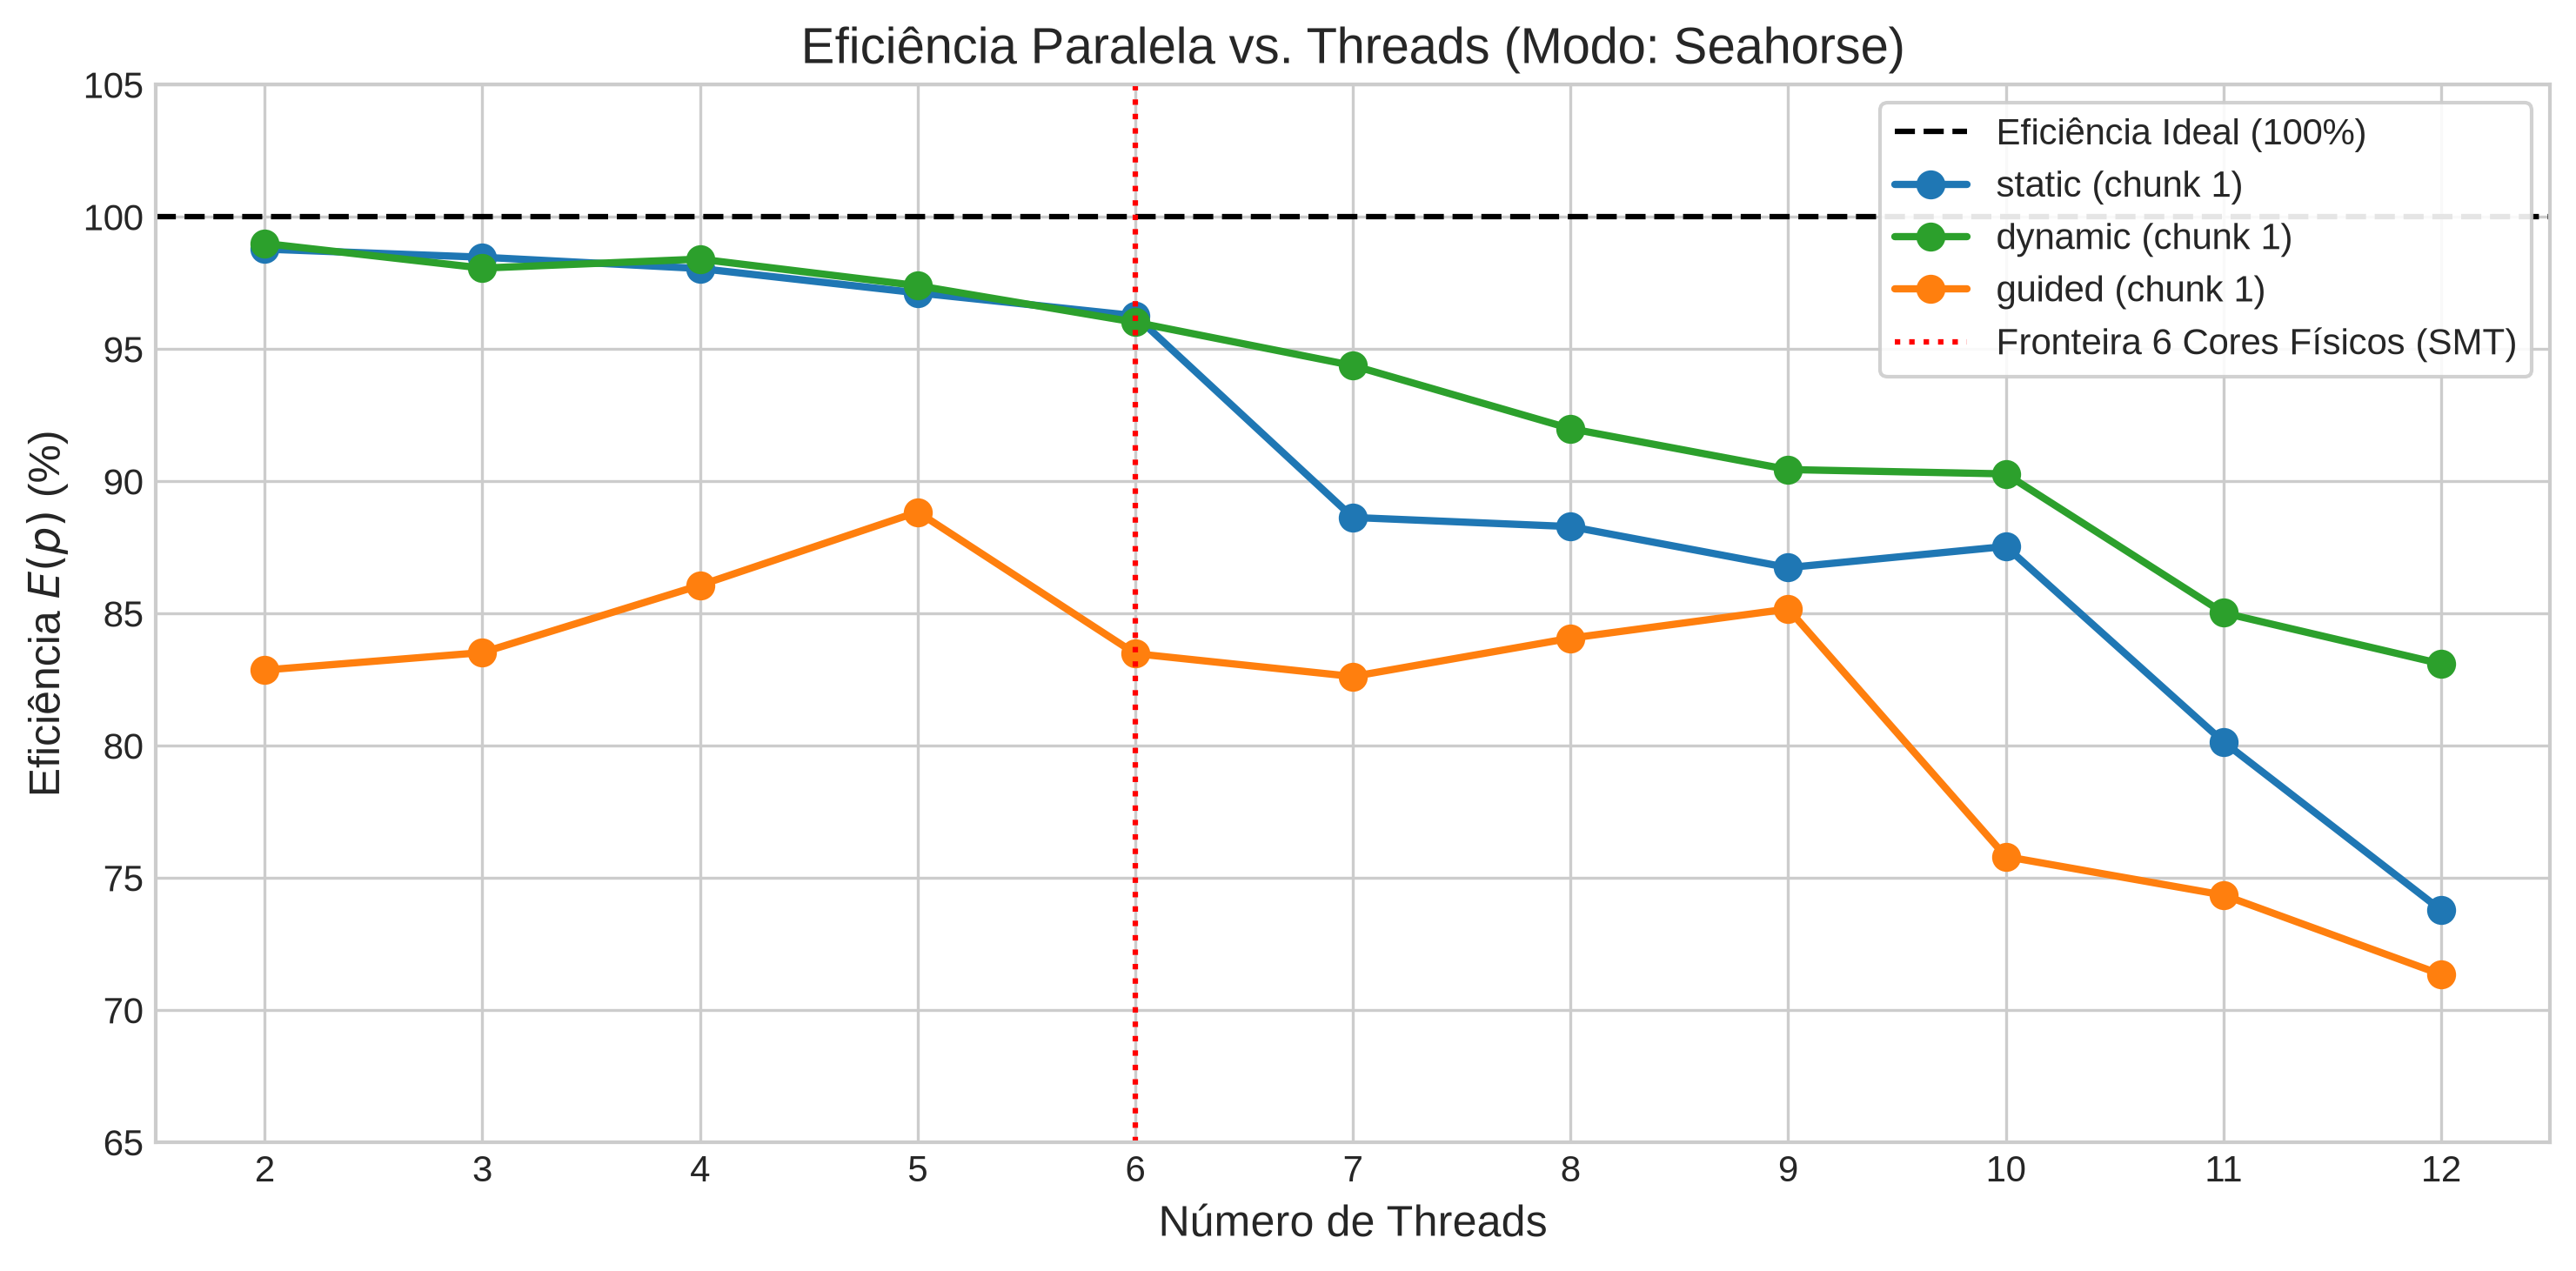

In [8]:


# Filtrando exclusivamente pelo modo 'seahorse' e chunk igual a 1
df_chunk1 = df_seahorse[(df_seahorse['modo'] == 'seahorse') & (df_seahorse['chunk'] == 1)]

# Calculando a média da eficiência e convertendo para porcentagem
grouped = df_chunk1.groupby(['threads', 'escalonamento'])['eficiencia'].mean().unstack() * 100

# Configurando o estilo visual
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(10, 5), dpi=300)

# Linhas de referência
plt.axhline(y=100, color='black', linestyle='--', linewidth=1.5, label='Eficiência Ideal (100%)')

# Plotando os dados com as mesmas cores e marcadores da referência
threads = grouped.index
plt.plot(threads, grouped['static'], marker='o', markersize=7, linewidth=2, color='tab:blue', label='static (chunk 1)')
plt.plot(threads, grouped['dynamic'], marker='o', markersize=7, linewidth=2, color='tab:green', label='dynamic (chunk 1)')
plt.plot(threads, grouped['guided'], marker='o', markersize=7, linewidth=2, color='tab:orange', label='guided (chunk 1)')

# Fronteira de Cores Físicos (SMT)
plt.axvline(x=6, color='red', linestyle=':', linewidth=1.5, label='Fronteira 6 Cores Físicos (SMT)')

# Configurações de layout
plt.title('Eficiência Paralela vs. Threads (Modo: Seahorse)', fontsize=14)
plt.xlabel('Número de Threads', fontsize=12)
plt.ylabel('Eficiência $E(p)$ (%)', fontsize=12)
plt.xticks(threads)
plt.ylim(65, 105)
plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()

plt.show()